# 07A2 — From Customer Orders to Efficient Deliveries
## TomTom real-time traffic + VRP + 3D packing as a hard feasibility constraint

**XtremePython 2026 demo — higher-demand Irvine + Lake Forest stress test**

This notebook models:

- 23 mock customers
- a **40-SKU hard-coded product master**
- an explicit **customer order table**
- each order line contains **SKU + quantity**
- physical boxes are generated from ordered quantities
- **2 Large Trucks + 3 Small Trucks (5 trucks total)**
- customer time windows
- **driver working shifts with soft overtime optimization**
- **driver-to-truck qualification constraints**
- a pre-dispatch **truck availability filter** based on staffing
- vehicle payload constraints
- aggregate volume constraints
- actual cargo-bed dimensions
- **3D bin-packing feasibility**
- iterative feedback from packing back into vehicle routing
- OpenStreetMap / OSMnx road network
- **TomTom Orbis real-time Traffic Flow Vector Tiles**
- traffic-aware edge travel times and customer-to-customer travel-time matrix
- final route and packing visualization

### Data flow

```text
TomTom real-time Traffic Flow
            +
      OSMnx road graph
            ↓
Traffic-aware edge travel times
            ↓
Product Master + Customer Orders
            ↓
Physical shipment boxes
            ↓
Customer total weight / aggregate volume
            ↓
Driver qualification + scheduled shifts
            ↓
Soft overtime penalty when a route returns late
            ↓
VRP
            ↓
3D Packing check for each assigned truck
            ↓
All FIT? ── YES ──> Accept
   │
   NO
   ↓
Add packing conflict cut
   ↓
Re-run VRP
```

### Optimization policy

The objective combines routing efficiency with workforce scheduling:

> Minimize **traffic-aware road travel time** while strongly minimizing **total driver overtime**.

But a route is accepted only when every assigned truck load is physically packable:

> **3D packing does not need to be optimal, but NOT FIT is unacceptable.**


### Version note

This **07A2** notebook keeps the **same optimization logic as 07A1**.

Only the scenario inputs are made more demanding:

- 20 → **23 customers**
- 3 additional mock customers in the **Lake Forest** area
- the 40-SKU product master is unchanged
- selected order quantities are increased
- total payload is intentionally pushed above the capacity of any 3-truck combination
- the road-network radius is expanded to cover the Lake Forest cluster

### Purpose

This is a stress-test scenario designed to make the optimizer use more of the available fleet and driver roster.

The optimization logic is unchanged:

- TomTom traffic-aware road times
- customer time windows
- payload / volume capacity
- driver qualification
- soft driver overtime
- 3D packing feedback cuts


# Chapter 1 — Same Model as 07A1

**Presentation role:** Difference-only demo.

The optimization architecture is intentionally the same as 07A1.  
Do **not** re-explain installation, imports, fleet logic, driver logic, packing logic, or the solver in detail.

## 1. Install packages

In [ ]:
!pip -q install "osmnx>=2.1,<3" ortools folium py3dbp mapbox-vector-tile

## 2. Imports and basic helpers

In [ ]:
import math
import requests
from collections import defaultdict
from datetime import datetime, timezone
import warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import networkx as nx
import folium
from IPython.display import display

import osmnx as ox
from ortools.constraint_solver import pywrapcp, routing_enums_pb2
from py3dbp import Packer, Bin, Item

import matplotlib.pyplot as plt
import mapbox_vector_tile
from google.colab import userdata

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# Customer source time windows in this demo are expressed as
# minutes from 08:00 (legacy input format).
CUSTOMER_DAY_START_HOUR = 8

# The optimization clock starts earlier so driver shifts such as
# 06:00-12:00 can be represented naturally.
SCHEDULE_ZERO_HOUR = 6
SCHEDULE_END_HOUR = 18
SCHEDULE_HORIZON_MIN = (
    SCHEDULE_END_HOUR - SCHEDULE_ZERO_HOUR
) * 60

CUSTOMER_TO_SCHEDULE_OFFSET_MIN = (
    CUSTOMER_DAY_START_HOUR - SCHEDULE_ZERO_HOUR
) * 60


def customer_hhmm(minutes_from_8am: int) -> str:
    """Display original customer-window minutes (0 = 08:00)."""
    total = (
        CUSTOMER_DAY_START_HOUR * 60
        + int(minutes_from_8am)
    )
    return f"{total // 60:02d}:{total % 60:02d}"


def hhmm(minutes_from_schedule_zero: int) -> str:
    """Display optimizer time (0 = 06:00)."""
    total = (
        SCHEDULE_ZERO_HOUR * 60
        + int(minutes_from_schedule_zero)
    )
    return f"{total // 60:02d}:{total % 60:02d}"


def clock_to_schedule_min(hhmm_text: str) -> int:
    """Convert 'HH:MM' to optimizer minutes from 06:00."""
    hour, minute = map(int, hhmm_text.split(":"))
    value = hour * 60 + minute - SCHEDULE_ZERO_HOUR * 60
    if value < 0 or value > SCHEDULE_HORIZON_MIN:
        raise ValueError(
            f"Time {hhmm_text} is outside the "
            f"{SCHEDULE_ZERO_HOUR:02d}:00-"
            f"{SCHEDULE_END_HOUR:02d}:00 planning horizon."
        )
    return value


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0088
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp = math.radians(lat2 - lat1)
    dl = math.radians(lon2 - lon1)
    a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * r * math.asin(math.sqrt(a))


def build_haversine_matrix(df):
    n = len(df)
    matrix = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(n):
            matrix[i, j] = haversine_km(
                df.loc[i, "lat"], df.loc[i, "lon"],
                df.loc[j, "lat"], df.loc[j, "lon"]
            )
    return matrix

# Chapter 2 — CHANGE 1: More Customers and Wider Geography

**Talk-script anchor: A2-CHANGE-CUSTOMERS**

**Explain this change.**

Compared with 07A1, this scenario adds customers / visits and expands the delivery area toward Lake Forest.

## 3. Customer locations, time windows, and service times

In [ ]:
# Index 0 is the warehouse/depot.
# 23 mock customers are used for the 06A2 higher-demand scenario.
#
# C21-C23 form an additional Lake Forest cluster.
# Their time windows are deliberately spread across the day:
#   C21 = morning
#   C22 = midday
#   C23 = late afternoon

locations = [
    ("DEPOT", "Distribution Center, Irvine, CA", 33.6846, -117.8265, 0,   0,   0),
    ("C01", "Mock Address 01, Irvine, CA", 33.6695, -117.8231, 0,   540, 12),
    ("C02", "Mock Address 02, Irvine, CA", 33.6500, -117.8420, 0,   540, 10),
    ("C03", "Mock Address 03, Irvine, CA", 33.6980, -117.7980, 240, 480, 12),
    ("C04", "Mock Address 04, Irvine, CA", 33.7050, -117.7740, 0,   540, 10),
    ("C05", "Mock Address 05, Irvine, CA", 33.7210, -117.7900, 60,  240, 10),
    ("C06", "Mock Address 06, Irvine, CA", 33.7170, -117.8310, 0,   540, 15),
    ("C07", "Mock Address 07, Irvine, CA", 33.7030, -117.8600, 180, 360, 10),
    ("C08", "Mock Address 08, Irvine, CA", 33.6880, -117.8650, 0,   540, 12),
    ("C09", "Mock Address 09, Irvine, CA", 33.6770, -117.8570, 240, 480, 10),
    ("C10", "Mock Address 10, Irvine, CA", 33.6650, -117.8580, 0,   540, 10),
    ("C11", "Mock Address 11, Irvine, CA", 33.6400, -117.8330, 0,   180, 15),
    ("C12", "Mock Address 12, Irvine, CA", 33.6470, -117.8070, 0,   540, 10),
    ("C13", "Mock Address 13, Irvine, CA", 33.6610, -117.7900, 300, 540, 12),
    ("C14", "Mock Address 14, Irvine, CA", 33.6750, -117.7850, 0,   540, 10),
    ("C15", "Mock Address 15, Irvine, CA", 33.6900, -117.7870, 120, 300, 15),
    ("C16", "Mock Address 16, Irvine, CA", 33.7140, -117.8080, 0,   540, 10),
    ("C17", "Mock Address 17, Irvine, CA", 33.7310, -117.8110, 240, 420, 12),
    ("C18", "Mock Address 18, Irvine, CA", 33.7360, -117.8450, 0,   540, 10),
    ("C19", "Mock Address 19, Irvine, CA", 33.7110, -117.8850, 60,  300, 12),
    ("C20", "Mock Address 20, Irvine, CA", 33.6800, -117.8930, 300, 540, 10),

    # Additional Lake Forest cluster for 06A2
    ("C21", "Mock Address 21, Lake Forest, CA", 33.6465, -117.7180, 0,   120, 15),  # 08:00-10:00
    ("C22", "Mock Address 22, Lake Forest, CA", 33.6460, -117.6890, 180, 300, 15),  # 11:00-13:00
    ("C23", "Mock Address 23, Lake Forest, CA", 33.6760, -117.6600, 480, 600, 15),  # 16:00-18:00
]

customer_df = pd.DataFrame(
    locations,
    columns=[
        "customer_id", "address", "lat", "lon",
        "window_start", "window_end", "service_min"
    ]
)

# 23 customers -> Customer A ... Customer W
customer_names = {
    f"C{i:02d}": f"Customer {chr(64+i)}"
    for i in range(1, len(locations))
}
customer_names["DEPOT"] = "Depot / Warehouse"

customer_df["customer_name"] = customer_df["customer_id"].map(customer_names)

customer_df["time_window"] = customer_df.apply(
    lambda r: f"{customer_hhmm(r.window_start)}-{customer_hhmm(r.window_end)}",
    axis=1
)

display(customer_df)


,customer_id,address,lat,lon,window_start,window_end,service_min,customer_name,time_window
0,DEPOT,"Distribution Center, Irvine, CA",33.6846,-117.8265,0,0,0,Depot / Warehouse,08:00-08:00
1,C01,"Mock Address 01, Irvine, CA",33.6695,-117.8231,0,540,12,Customer A,08:00-17:00
2,C02,"Mock Address 02, Irvine, CA",33.6500,-117.8420,0,540,10,Customer B,08:00-17:00
3,C03,"Mock Address 03, Irvine, CA",33.6980,-117.7980,240,480,12,Customer C,12:00-16:00
4,C04,"Mock Address 04, Irvine, CA",33.7050,-117.7740,0,540,10,Customer D,08:00-17:00
5,C05,"Mock Address 05, Irvine, CA",33.7210,-117.7900,60,240,10,Customer E,09:00-12:00
6,C06,"Mock Address 06, Irvine, CA",33.7170,-117.8310,0,540,15,Customer F,08:00-17:00
7,C07,"Mock Address 07, Irvine, CA",33.7030,-117.8600,180,360,10,Customer G,11:00-14:00
8,C08,"Mock Address 08, Irvine, CA",33.6880,-117.8650,0,540,12,Customer H,08:00-17:00
9,C09,"Mock Address 09, Irvine, CA",33.6770,-117.8570,240,480,10,Customer I,12:00-16:00


## 4. Hard-coded product master — 40 SKUs

The product master is independent of customers.

Each SKU defines:

- SKU / product name
- shape
- Length × Width × Height
- unit weight
- unit volume

All products in this version are **rectangular cuboid boxes**.

Some SKUs are intentionally longer than the Small Truck's 300 cm cargo-bed length.  
A customer ordering one of those SKUs may pass a simple aggregate-volume test but still fail the physical 3D Packing check.

In [ ]:
# Units:
#   dimensions = cm
#   weight = kg
#
# This is the PRODUCT MASTER.
# No customer assignment is stored here.

products = [
    ("SKU001","Standard Carton S","BOX", 60, 40, 35, 12),
    ("SKU002","Long Equipment A","BOX",310, 50, 40, 36),  # too long for Small Truck
    ("SKU003","Standard Carton M","BOX", 80, 55, 45, 18),
    ("SKU004","Standard Carton L","BOX",110, 70, 60, 28),
    ("SKU005","Bulk Carton A","BOX",100, 80, 65, 32),
    ("SKU006","Long Equipment B","BOX",320, 55, 45, 42),  # too long for Small Truck
    ("SKU007","Machine Case A","BOX",120, 75, 70, 35),
    ("SKU008","Parts Carton A","BOX", 85, 60, 55, 16),
    ("SKU009","Parts Carton B","BOX", 95, 70, 60, 22),
    ("SKU010","Long Equipment C","BOX",325, 45, 40, 30),  # too long for Small Truck
    ("SKU011","Machine Case B","BOX",130, 80, 70, 38),
    ("SKU012","Parts Carton C","BOX", 90, 60, 50, 20),
    ("SKU013","Bulk Carton B","BOX",105, 75, 65, 26),
    ("SKU014","Long Equipment D","BOX",330, 50, 45, 44),  # too long for Small Truck
    ("SKU015","Machine Case C","BOX",115, 75, 60, 30),
    ("SKU016","Standard Carton XS","BOX", 55, 40, 35, 10),
    ("SKU017","Bulk Carton C","BOX",100, 70, 60, 24),
    ("SKU018","Parts Carton D","BOX", 75, 55, 50, 15),
    ("SKU019","Machine Case D","BOX",125, 80, 65, 34),
    ("SKU020","Long Equipment E","BOX",315, 50, 45, 40),  # too long for Small Truck
    ("SKU021","Bulk Carton D","BOX",105, 75, 70, 27),
    ("SKU022","Parts Carton E","BOX", 80, 55, 45, 16),
    ("SKU023","Machine Case E","BOX",115, 75, 65, 31),
    ("SKU024","Long Equipment F","BOX",340, 50, 40, 46),  # too long for Small Truck
    ("SKU025","Bulk Carton E","BOX",100, 80, 70, 29),
    ("SKU026","Parts Carton F","BOX", 85, 60, 50, 18),
    ("SKU027","Machine Case F","BOX",120, 75, 65, 33),
    ("SKU028","Standard Carton XXS","BOX", 50, 35, 30,  8),
    ("SKU029","Bulk Carton F","BOX",110, 70, 60, 25),
    ("SKU030","Parts Carton G","BOX", 90, 65, 55, 19),
    ("SKU031","Machine Case G","BOX",130, 80, 70, 37),
    ("SKU032","Parts Carton H","BOX", 85, 60, 50, 17),
    ("SKU033","Bulk Carton G","BOX",105, 75, 65, 26),
    ("SKU034","Long Equipment G","BOX",315, 60, 45, 43),  # too long for Small Truck
    ("SKU035","Machine Case H","BOX",115, 80, 70, 32),
    ("SKU036","Standard Carton S2","BOX", 65, 45, 40, 13),
    ("SKU037","Machine Case I","BOX",125, 75, 65, 34),
    ("SKU038","Parts Carton I","BOX", 90, 65, 55, 18),
    ("SKU039","Bulk Carton H","BOX",100, 70, 60, 23),
    ("SKU040","Long Equipment H","BOX",335, 45, 40, 39),  # too long for Small Truck
]

product_df = pd.DataFrame(
    products,
    columns=[
        "sku", "product_name", "shape",
        "length_cm", "width_cm", "height_cm", "unit_weight_kg"
    ]
)

product_df["unit_volume_cm3"] = (
    product_df["length_cm"]
    * product_df["width_cm"]
    * product_df["height_cm"]
)
product_df["unit_volume_liters"] = product_df["unit_volume_cm3"] / 1000.0

display(product_df)

print("SKUs in product master:", len(product_df))

,sku,product_name,shape,length_cm,width_cm,height_cm,unit_weight_kg,unit_volume_cm3,unit_volume_liters
0,SKU001,Standard Carton S,BOX,60,40,35,12,84000,84.000
1,SKU002,Long Equipment A,BOX,310,50,40,36,620000,620.000
2,SKU003,Standard Carton M,BOX,80,55,45,18,198000,198.000
3,SKU004,Standard Carton L,BOX,110,70,60,28,462000,462.000
4,SKU005,Bulk Carton A,BOX,100,80,65,32,520000,520.000
5,SKU006,Long Equipment B,BOX,320,55,45,42,792000,792.000
6,SKU007,Machine Case A,BOX,120,75,70,35,630000,630.000
7,SKU008,Parts Carton A,BOX,85,60,55,16,280500,280.500
8,SKU009,Parts Carton B,BOX,95,70,60,22,399000,399.000
9,SKU010,Long Equipment C,BOX,325,45,40,30,585000,585.000


SKUs in product master: 40


# Chapter 3 — CHANGE 2: Higher Order Demand

**Talk-script anchor: A2-CHANGE-ORDERS**

**Explain this change.**

The product master stays the same, but order quantities and total physical demand are increased.

## 5. Customer order table — who ordered what, and how many?

This is the missing business layer between customers and physical cargo.

Each line explicitly defines:

- `order_id`
- `customer_id`
- `sku`
- `quantity`

For example:

```text
Customer A
  SKU001 × 2
  SKU002 × 1
```

The routing model does **not** route SKUs directly.  
It routes customers after aggregating the weight and volume of all ordered units for each customer.

The packing model then expands every ordered quantity back into individual physical boxes.

In [ ]:
# Hard-coded ORDER LINES — 06A2 stress-test scenario.
#
# The 40-SKU product master is UNCHANGED.
# We only:
#   1) increase selected quantities for existing customers
#   2) add orders for C21-C23
#
# The resulting total payload is intentionally > 2,500 kg.
# Since the three largest truck payload capacities are:
#   1000 + 1000 + 500 = 2500 kg
# at least FOUR trucks are required by payload alone.

orders = [
    ("ORD-C01","C01","SKU001",2), ("ORD-C01","C01","SKU002",1),
    ("ORD-C02","C02","SKU003",3), ("ORD-C02","C02","SKU004",1),
    ("ORD-C03","C03","SKU005",2), ("ORD-C03","C03","SKU006",1),

    # Increased SKU008 quantity: 3 -> 6
    ("ORD-C04","C04","SKU007",1), ("ORD-C04","C04","SKU008",6),

    ("ORD-C05","C05","SKU009",2), ("ORD-C05","C05","SKU010",1),
    ("ORD-C06","C06","SKU011",1), ("ORD-C06","C06","SKU012",3),
    ("ORD-C07","C07","SKU013",2), ("ORD-C07","C07","SKU014",1),

    # Increased SKU016 quantity: 4 -> 10
    ("ORD-C08","C08","SKU015",1), ("ORD-C08","C08","SKU016",10),

    # Increased SKU018 quantity: 3 -> 7
    ("ORD-C09","C09","SKU017",2), ("ORD-C09","C09","SKU018",7),

    ("ORD-C10","C10","SKU019",1), ("ORD-C10","C10","SKU020",1),
    ("ORD-C11","C11","SKU021",2), ("ORD-C11","C11","SKU022",3),
    ("ORD-C12","C12","SKU023",1), ("ORD-C12","C12","SKU024",1),
    ("ORD-C13","C13","SKU025",2), ("ORD-C13","C13","SKU026",2),

    # Increased SKU028 quantity: 4 -> 10
    ("ORD-C14","C14","SKU027",1), ("ORD-C14","C14","SKU028",10),

    ("ORD-C15","C15","SKU029",2), ("ORD-C15","C15","SKU030",3),

    # Increased SKU032 quantity: 3 -> 7
    ("ORD-C16","C16","SKU031",1), ("ORD-C16","C16","SKU032",7),

    ("ORD-C17","C17","SKU033",2), ("ORD-C17","C17","SKU034",1),
    ("ORD-C18","C18","SKU035",1), ("ORD-C18","C18","SKU036",4),
    ("ORD-C19","C19","SKU037",1), ("ORD-C19","C19","SKU038",3),
    ("ORD-C20","C20","SKU039",2), ("ORD-C20","C20","SKU040",1),

    # New Lake Forest customers.
    # All use existing SKUs that individually fit a Small Truck.
    ("ORD-C21","C21","SKU011",3), ("ORD-C21","C21","SKU012",5),
    ("ORD-C22","C22","SKU019",3), ("ORD-C22","C22","SKU018",6),
    ("ORD-C23","C23","SKU031",3), ("ORD-C23","C23","SKU032",6),
]

order_df = pd.DataFrame(
    orders,
    columns=["order_id", "customer_id", "sku", "quantity"]
)

# Attach customer name and product attributes.
order_detail_df = (
    order_df
    .merge(
        customer_df[["customer_id", "customer_name"]],
        on="customer_id",
        how="left"
    )
    .merge(
        product_df,
        on="sku",
        how="left"
    )
)

order_detail_df["line_weight_kg"] = (
    order_detail_df["quantity"]
    * order_detail_df["unit_weight_kg"]
)

order_detail_df["line_volume_liters"] = (
    order_detail_df["quantity"]
    * order_detail_df["unit_volume_liters"]
)

display(order_detail_df[[
    "order_id", "customer_id", "customer_name",
    "sku", "product_name", "quantity",
    "length_cm", "width_cm", "height_cm",
    "unit_weight_kg", "line_weight_kg",
    "line_volume_liters"
]])

print("Order lines:", len(order_df))
print("Physical units ordered:", int(order_df["quantity"].sum()))


,order_id,customer_id,customer_name,sku,product_name,quantity,length_cm,width_cm,height_cm,unit_weight_kg,line_weight_kg,line_volume_liters
0,ORD-C01,C01,Customer A,SKU001,Standard Carton S,2,60,40,35,12,24,168.000
1,ORD-C01,C01,Customer A,SKU002,Long Equipment A,1,310,50,40,36,36,620.000
2,ORD-C02,C02,Customer B,SKU003,Standard Carton M,3,80,55,45,18,54,594.000
3,ORD-C02,C02,Customer B,SKU004,Standard Carton L,1,110,70,60,28,28,462.000
4,ORD-C03,C03,Customer C,SKU005,Bulk Carton A,2,100,80,65,32,64,1040.000
5,ORD-C03,C03,Customer C,SKU006,Long Equipment B,1,320,55,45,42,42,792.000
6,ORD-C04,C04,Customer D,SKU007,Machine Case A,1,120,75,70,35,35,630.000
7,ORD-C04,C04,Customer D,SKU008,Parts Carton A,6,85,60,55,16,96,1683.000
8,ORD-C05,C05,Customer E,SKU009,Parts Carton B,2,95,70,60,22,44,798.000
9,ORD-C05,C05,Customer E,SKU010,Long Equipment C,1,325,45,40,30,30,585.000


Order lines: 46
Physical units ordered: 125


# Chapter 4 — SAME Optimization Core as 07A1

**Talk-script anchor: A2-SAME-CORE**

**Skip detailed explanation in the live talk.**

Truck definitions, drivers, time windows, TomTom/OSM road-cost logic, VRP constraints, soft overtime, and 3D-packing feedback use the same architecture as 07A1.

## 6. Truck fleet — two Large Trucks and three Small Trucks

In [ ]:
# Truck dimensions are INTERNAL cargo-bed dimensions.
# This is demo data, not a specification for a particular real truck model.
#
# Fleet:
#   Truck 1-2 = LARGE
#   Truck 3-5 = SMALL
#
# All five trucks are AVAILABLE to the optimizer.
# A truck may remain unused if the routing solution does not need it.

trucks = [
    # vehicle_id, truck_name, type, length, width, height, max_payload
    (0, "Truck 1", "LARGE", 450, 220, 220, 1000),
    (1, "Truck 2", "LARGE", 450, 220, 220, 1000),
    (2, "Truck 3", "SMALL", 300, 170, 170,  500),
    (3, "Truck 4", "SMALL", 300, 170, 170,  500),
    (4, "Truck 5", "SMALL", 300, 170, 170,  500),
]

truck_df = pd.DataFrame(
    trucks,
    columns=[
        "vehicle_id", "truck_name", "truck_type",
        "length_cm", "width_cm", "height_cm", "max_payload_kg"
    ]
)

truck_df["cargo_volume_liters"] = (
    truck_df["length_cm"]
    * truck_df["width_cm"]
    * truck_df["height_cm"]
    / 1000.0
)
truck_df["cargo_volume_m3"] = truck_df["cargo_volume_liters"] / 1000.0

display(truck_df)

print("Fleet size:", len(truck_df), "trucks")
print(
    "Large / Small:",
    int((truck_df["truck_type"] == "LARGE").sum()),
    "/",
    int((truck_df["truck_type"] == "SMALL").sum())
)
print("Fleet payload capacity:", truck_df["max_payload_kg"].sum(), "kg")
print(
    "Fleet geometric volume:",
    round(truck_df["cargo_volume_m3"].sum(), 2),
    "m³"
)

,vehicle_id,truck_name,truck_type,length_cm,width_cm,height_cm,max_payload_kg,cargo_volume_liters,cargo_volume_m3
0,0,Truck 1,LARGE,450,220,220,1000,21780.0,21.78
1,1,Truck 2,LARGE,450,220,220,1000,21780.0,21.78
2,2,Truck 3,SMALL,300,170,170,500,8670.0,8.67
3,3,Truck 4,SMALL,300,170,170,500,8670.0,8.67
4,4,Truck 5,SMALL,300,170,170,500,8670.0,8.67


Fleet size: 5 trucks
Large / Small: 2 / 3
Fleet payload capacity: 3500 kg
Fleet geometric volume: 69.57 m³


## Driver roster and working-shift constraints

The trucks and drivers are modeled as separate business inputs.

For this  demo, each truck is assigned one qualified driver before optimization.

The route optimizer treats the **start of the driver shift as a hard constraint**, but the scheduled shift end is a **soft constraint**:

> Returning after the scheduled shift end is allowed, but every overtime minute is penalized.

This lets the model produce a feasible delivery plan instead of failing immediately when a small amount of overtime is unavoidable.

The final report shows overtime by driver so a dispatcher can consider:

- swapping shifts,
- reassigning a route,
- asking another qualified driver to cover,
- or accepting the overtime when it is operationally reasonable.

> This version models one continuous shift per driver. Breaks and split shifts remain possible extensions.


In [ ]:
# ============================================================
# DRIVER ROSTER + TRUCK QUALIFICATIONS
# ============================================================
#
# Scenario for the  demo:
#
#   Driver A  FULL_TIME  06:00-15:00  SMALL + LARGE
#   Driver B  FULL_TIME  07:00-16:00  SMALL + LARGE
#   Driver C  FULL_TIME  08:00-17:00  SMALL + LARGE
#   Driver D  PART_TIME  07:00-12:00  SMALL only
#   Driver E  PART_TIME  13:00-18:00  SMALL only
#
# The dispatcher first determines which physical trucks can be
# staffed by qualified drivers. The VRP is solved only after those
# truck operating windows are fixed.

drivers = [
    # driver_id, driver_name, employment, shift_start, shift_end,
    # can_small, can_large
    ("D01", "Driver A", "FULL_TIME", "06:00", "15:00", True,  True),
    ("D02", "Driver B", "FULL_TIME", "07:00", "16:00", True,  True),
    ("D03", "Driver C", "FULL_TIME", "08:00", "17:00", True,  True),
    ("D04", "Driver D", "PART_TIME", "07:00", "12:00", True,  False),
    ("D05", "Driver E", "PART_TIME", "13:00", "18:00", True,  False),
]

driver_df = pd.DataFrame(
    drivers,
    columns=[
        "driver_id",
        "driver_name",
        "employment",
        "shift_start",
        "shift_end",
        "can_small",
        "can_large",
    ]
)

driver_df["shift_start_min"] = (
    driver_df["shift_start"].map(clock_to_schedule_min)
)
driver_df["shift_end_min"] = (
    driver_df["shift_end"].map(clock_to_schedule_min)
)
driver_df["shift_hours"] = (
    driver_df["shift_end_min"]
    - driver_df["shift_start_min"]
) / 60.0

driver_df["qualification"] = np.where(
    driver_df["can_large"],
    "SMALL + LARGE",
    "SMALL only"
)

display(
    driver_df[[
        "driver_name",
        "employment",
        "qualification",
        "shift_start",
        "shift_end",
        "shift_hours",
    ]]
)


# ============================================================
# DRIVER x TRUCK COMPATIBILITY
# ============================================================

def can_drive(driver_row, truck_type):
    if truck_type == "LARGE":
        return bool(driver_row["can_large"])
    if truck_type == "SMALL":
        return bool(driver_row["can_small"])
    return False


compatibility_rows = []

for _, d in driver_df.iterrows():
    for _, t in truck_df.iterrows():
        compatibility_rows.append({
            "driver_id": d["driver_id"],
            "driver": d["driver_name"],
            "shift": f"{d['shift_start']}-{d['shift_end']}",
            "truck_id": int(t["vehicle_id"]),
            "truck": t["truck_name"],
            "truck_type": t["truck_type"],
            "qualified": can_drive(d, t["truck_type"]),
        })

driver_truck_compatibility_df = pd.DataFrame(
    compatibility_rows
)

print("Driver / Truck qualification matrix:")
display(
    driver_truck_compatibility_df.pivot(
        index=["driver", "shift"],
        columns=["truck", "truck_type"],
        values="qualified",
    )
)


# ============================================================
# PRE-DISPATCH STAFFING FILTER
# ============================================================
#
# The driver/truck roster is fixed BEFORE the VRP.
#
# We deliberately assign the earliest and latest full-time drivers
# to the two LARGE trucks so that LARGE-truck coverage spans most
# of the delivery day:
#
#   Truck 1 LARGE <- Driver A 06:00-15:00
#   Truck 2 LARGE <- Driver C 08:00-17:00
#   Truck 3 SMALL <- Driver B 07:00-16:00
#   Truck 4 SMALL <- Driver D 07:00-12:00
#   Truck 5 SMALL <- Driver E 13:00-18:00
#
# The qualification table above is still authoritative. If a planned
# pairing is not qualified, that physical truck is marked UNAVAILABLE
# and the VRP cannot assign customers to it.

planned_dispatch = pd.DataFrame([
    # vehicle_id, driver_id
    (0, "D01"),  # LARGE <- full-time / early
    (1, "D03"),  # LARGE <- full-time / late
    (2, "D02"),  # SMALL <- full-time / middle
    (3, "D04"),  # SMALL <- part-time / morning
    (4, "D05"),  # SMALL <- part-time / afternoon
], columns=[
    "vehicle_id",
    "driver_id",
])

assignment_rows = []

for _, plan in planned_dispatch.iterrows():
    vehicle_id = int(plan["vehicle_id"])
    driver_id = plan["driver_id"]

    truck = truck_df.loc[
        truck_df["vehicle_id"] == vehicle_id
    ].iloc[0]

    driver = driver_df.loc[
        driver_df["driver_id"] == driver_id
    ].iloc[0]

    qualified = can_drive(
        driver,
        truck["truck_type"],
    )

    assignment_rows.append({
        "vehicle_id": vehicle_id,
        "driver_id": driver_id if qualified else None,
        "available": bool(qualified),
        "staffing_note": (
            "QUALIFIED"
            if qualified
            else "UNAVAILABLE - DRIVER NOT QUALIFIED"
        ),
    })


truck_driver_assignment = pd.DataFrame(
    assignment_rows
)

vehicle_driver_df = (
    truck_df
    .merge(
        truck_driver_assignment,
        on="vehicle_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        driver_df,
        on="driver_id",
        how="left",
        validate="many_to_one",
    )
    .sort_values("vehicle_id")
    .reset_index(drop=True)
)

vehicle_driver_df["availability"] = np.where(
    vehicle_driver_df["available"].fillna(False),
    "AVAILABLE",
    "UNAVAILABLE",
)

# IMPORTANT:
# OR-Tools SetAllowedVehiclesForIndex() requires a Python sequence
# of native int values. Pandas/NumPy integer scalars can trigger:
#   TypeError: argument 2 of type 'absl::Span< int const >'
available_vehicle_ids = [
    int(v)
    for v in vehicle_driver_df.loc[
        vehicle_driver_df["available"].fillna(False),
        "vehicle_id",
    ].tolist()
]

print("Pre-dispatch truck availability after qualification filtering:")
display(
    vehicle_driver_df[[
        "vehicle_id",
        "truck_name",
        "truck_type",
        "availability",
        "driver_name",
        "employment",
        "qualification",
        "shift_start",
        "shift_end",
        "staffing_note",
    ]]
)

print(
    "Available trucks:",
    len(available_vehicle_ids),
    "/",
    len(truck_df),
)
print(
    "OR-Tools vehicle IDs:",
    available_vehicle_ids,
    "| Python types:",
    [type(v).__name__ for v in available_vehicle_ids],
)

if len(available_vehicle_ids) == 0:
    raise RuntimeError(
        "NO OPERATING TRUCKS: no qualified driver/truck pair is available."
    )


,driver_name,employment,qualification,shift_start,shift_end,shift_hours
0,Driver A,FULL_TIME,SMALL + LARGE,06:00,15:00,9.0
1,Driver B,FULL_TIME,SMALL + LARGE,07:00,16:00,9.0
2,Driver C,FULL_TIME,SMALL + LARGE,08:00,17:00,9.0
3,Driver D,PART_TIME,SMALL only,07:00,12:00,5.0
4,Driver E,PART_TIME,SMALL only,13:00,18:00,5.0


Driver / Truck qualification matrix:


,truck,Truck 1,Truck 2,Truck 3,Truck 4,Truck 5
,truck_type,LARGE,LARGE,SMALL,SMALL,SMALL
driver,shift,,,,,
Driver A,06:00-15:00,True,True,True,True,True
Driver B,07:00-16:00,True,True,True,True,True
Driver C,08:00-17:00,True,True,True,True,True
Driver D,07:00-12:00,False,False,True,True,True
Driver E,13:00-18:00,False,False,True,True,True


Pre-dispatch truck availability after qualification filtering:


,vehicle_id,truck_name,truck_type,availability,driver_name,employment,qualification,shift_start,shift_end,staffing_note
0,0,Truck 1,LARGE,AVAILABLE,Driver A,FULL_TIME,SMALL + LARGE,06:00,15:00,QUALIFIED
1,1,Truck 2,LARGE,AVAILABLE,Driver C,FULL_TIME,SMALL + LARGE,08:00,17:00,QUALIFIED
2,2,Truck 3,SMALL,AVAILABLE,Driver B,FULL_TIME,SMALL + LARGE,07:00,16:00,QUALIFIED
3,3,Truck 4,SMALL,AVAILABLE,Driver D,PART_TIME,SMALL only,07:00,12:00,QUALIFIED
4,4,Truck 5,SMALL,AVAILABLE,Driver E,PART_TIME,SMALL only,13:00,18:00,QUALIFIED


Available trucks: 5 / 5
OR-Tools vehicle IDs: [0, 1, 2, 3, 4] | Python types: ['int', 'int', 'int', 'int', 'int']


## 7. Convert order lines into VRP customer demand

For VRP, all order lines for the same customer are aggregated into:

- total shipment weight
- total aggregate volume
- total physical box count

This is the **fast routing-level capacity check**.

The real 3D geometry is checked later.

In [ ]:
customer_demand = (
    order_detail_df.groupby("customer_id", as_index=False)
    .agg(
        weight_kg=("line_weight_kg", "sum"),
        volume_liters=("line_volume_liters", "sum"),
        box_count=("quantity", "sum"),
        sku_count=("sku", "nunique")
    )
)

customer_df = customer_df.merge(
    customer_demand,
    on="customer_id",
    how="left"
)

customer_df[
    ["weight_kg", "volume_liters", "box_count", "sku_count"]
] = customer_df[
    ["weight_kg", "volume_liters", "box_count", "sku_count"]
].fillna(0)

customer_df["weight_kg"] = customer_df["weight_kg"].astype(int)
customer_df["volume_liters"] = customer_df["volume_liters"].round().astype(int)
customer_df["box_count"] = customer_df["box_count"].astype(int)
customer_df["sku_count"] = customer_df["sku_count"].astype(int)

display(customer_df[[
    "customer_id", "customer_name",
    "time_window", "service_min",
    "sku_count", "box_count",
    "weight_kg", "volume_liters"
]])

print("Total order weight:", int(customer_df["weight_kg"].sum()), "kg")
print(
    "Total aggregate order volume:",
    round(customer_df["volume_liters"].sum() / 1000, 2),
    "m³"
)

,customer_id,customer_name,time_window,service_min,sku_count,box_count,weight_kg,volume_liters
0,DEPOT,Depot / Warehouse,08:00-08:00,0,0,0,0,0
1,C01,Customer A,08:00-17:00,12,2,3,60,788
2,C02,Customer B,08:00-17:00,10,2,4,82,1056
3,C03,Customer C,12:00-16:00,12,2,3,106,1832
4,C04,Customer D,08:00-17:00,10,2,7,131,2313
5,C05,Customer E,09:00-12:00,10,2,3,74,1383
6,C06,Customer F,08:00-17:00,15,2,4,98,1538
7,C07,Customer G,11:00-14:00,10,2,3,96,1766
8,C08,Customer H,08:00-17:00,12,2,11,130,1288
9,C09,Customer I,12:00-16:00,10,2,9,153,2284


Total order weight: 2624 kg
Total aggregate order volume: 42.13 m³


## 8. Expand ordered quantities into physical boxes

An order line such as:

```text
Customer B | SKU003 | quantity = 3
```

becomes three physical packing items:

```text
ORD-C02-SKU003-001
ORD-C02-SKU003-002
ORD-C02-SKU003-003
```

These individual boxes are what the 3D Packing algorithm actually loads into a truck.

In [ ]:
physical_items = []

for _, row in order_detail_df.iterrows():
    for unit_no in range(1, int(row["quantity"]) + 1):
        physical_items.append({
            "item_id": (
                f"{row['order_id']}-{row['sku']}-{unit_no:03d}"
            ),
            "order_id": row["order_id"],
            "customer_id": row["customer_id"],
            "customer_name": row["customer_name"],
            "sku": row["sku"],
            "product_name": row["product_name"],
            "shape": row["shape"],
            "length_cm": int(row["length_cm"]),
            "width_cm": int(row["width_cm"]),
            "height_cm": int(row["height_cm"]),
            "weight_kg": int(row["unit_weight_kg"]),
            "volume_liters": float(row["unit_volume_liters"])
        })

physical_item_df = pd.DataFrame(physical_items)

display(physical_item_df.head(20))

print("Physical boxes to deliver:", len(physical_item_df))
print(
    "Physical box weight total:",
    int(physical_item_df["weight_kg"].sum()),
    "kg"
)

,item_id,order_id,customer_id,customer_name,sku,product_name,shape,length_cm,width_cm,height_cm,weight_kg,volume_liters
0,ORD-C01-SKU001-001,ORD-C01,C01,Customer A,SKU001,Standard Carton S,BOX,60,40,35,12,84.0
1,ORD-C01-SKU001-002,ORD-C01,C01,Customer A,SKU001,Standard Carton S,BOX,60,40,35,12,84.0
2,ORD-C01-SKU002-001,ORD-C01,C01,Customer A,SKU002,Long Equipment A,BOX,310,50,40,36,620.0
3,ORD-C02-SKU003-001,ORD-C02,C02,Customer B,SKU003,Standard Carton M,BOX,80,55,45,18,198.0
4,ORD-C02-SKU003-002,ORD-C02,C02,Customer B,SKU003,Standard Carton M,BOX,80,55,45,18,198.0
5,ORD-C02-SKU003-003,ORD-C02,C02,Customer B,SKU003,Standard Carton M,BOX,80,55,45,18,198.0
6,ORD-C02-SKU004-001,ORD-C02,C02,Customer B,SKU004,Standard Carton L,BOX,110,70,60,28,462.0
7,ORD-C03-SKU005-001,ORD-C03,C03,Customer C,SKU005,Bulk Carton A,BOX,100,80,65,32,520.0
8,ORD-C03-SKU005-002,ORD-C03,C03,Customer C,SKU005,Bulk Carton A,BOX,100,80,65,32,520.0
9,ORD-C03-SKU006-001,ORD-C03,C03,Customer C,SKU006,Long Equipment B,BOX,320,55,45,42,792.0


Physical boxes to deliver: 125
Physical box weight total: 2624 kg


## 9. Plot the depot and customer locations

In [ ]:
center = [
    customer_df["lat"].mean(),
    customer_df["lon"].mean()
]

# IMPORTANT:
# Do not use tiles="OpenStreetMap"
# Do not use tiles="CartoDB positron"
point_map = folium.Map(
    location=center,
    zoom_start=11,
    tiles=None
)

# Same basemap that worked for the final route map
folium.TileLayer(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors",
    name="OpenStreetMap.DE",
    overlay=False,
    control=False,
    max_zoom=18
).add_to(point_map)


for _, row in customer_df.iterrows():

    if row.customer_id == "DEPOT":

        folium.Marker(
            [row.lat, row.lon],
            tooltip="DEPOT / WAREHOUSE",
            popup=(
                "<b>DEPOT / WAREHOUSE</b><br>"
                "Driver-dependent departure<br>"
                "Return within assigned driver shift"
            ),
            icon=folium.Icon(
                color="black",
                icon="home",
                prefix="fa"
            )
        ).add_to(point_map)

    else:

        customer_orders = order_detail_df[
            order_detail_df["customer_id"] == row.customer_id
        ]

        order_text = "<br>".join(
            f"{r.sku} {r.product_name} × {int(r.quantity)}"
            for _, r in customer_orders.iterrows()
        )

        popup = (
            f"<b>{row.customer_name} ({row.customer_id})</b><br>"
            f"{row.address}<br><br>"
            f"<b>Order</b><br>{order_text}<br><br>"
            f"Boxes: {row.box_count}<br>"
            f"Weight: {row.weight_kg} kg<br>"
            f"Aggregate volume: {row.volume_liters} L<br>"
            f"Time window: {row.time_window}<br>"
            f"Service: {row.service_min} min"
        )

        folium.CircleMarker(
            [row.lat, row.lon],
            radius=6,
            fill=True,
            fill_opacity=0.8,
            tooltip=(
                f"{row.customer_name} / "
                f"{row.customer_id}"
            ),
            popup=popup
        ).add_to(point_map)

point_map

## 10. Road network + TomTom traffic — three-level cache

This version minimizes network calls and repeated computation.

**Priority order**

1. **MERGED cache first**
   - If a compatible cached result exists, load the traffic-applied OSM graph and all customer matrices.
   - TomTom API calls = 0.
   - OSM download = 0.
   - TomTom → OSM map matching = skipped.
   - Dijkstra matrix building = skipped.

2. **TomTom raw traffic cache**
   - If no MERGED cache exists, load raw TomTom PBF tiles from LOCAL first, then Google Drive.
   - Only missing tiles are downloaded from TomTom.
   - The completed raw snapshot is saved back to Google Drive.

3. **Base OSM graph cache**
   - Load the base OSM graph from LOCAL first, then Google Drive.
   - If absent, download/build it once and save it to Google Drive.

4. **Merge + save**
   - Apply the cached TomTom traffic to the cached/base OSM graph.
   - Build baseline and traffic-aware customer matrices.
   - Save the entire merged result to LOCAL + Google Drive.

Google Drive cache directory:

`/content/drive/MyDrive/プレゼン発表/ExtremePython_2026-11-16/tomtom_cache`


In [ ]:
# ============================================================
# 10A. CACHE CONFIG + TRY MERGED RESULT FIRST
# ============================================================

from google.colab import drive
from pathlib import Path
import gzip
import pickle
import shutil
import os
import json
import hashlib

drive.mount("/content/drive", force_remount=False)

# ------------------------------------------------------------
# Cache directories
# ------------------------------------------------------------

# Google Drive cache directory.
# Change this path to a folder in your own Google Drive before running the notebook.
# Example:
#   /content/drive/MyDrive/delivery-vrp/tomtom_cache
CACHE_DIR_DRIVE = Path(
    "/content/drive/MyDrive/プレゼン発表/ExtremePython_2026-11-16/tomtom_cache"
)

CACHE_DIR_LOCAL = Path(
    "/content/tomtom_cache"
)

CACHE_DIR_DRIVE.mkdir(parents=True, exist_ok=True)
CACHE_DIR_LOCAL.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Main settings
# ------------------------------------------------------------
USE_OSM = True
USE_TOMTOM_TRAFFIC = True

OSM_DOWNLOAD_RADIUS_M = 18_000
TOMTOM_TRAFFIC_ZOOM = 14
TOMTOM_CLOSED_EDGE_PENALTY_SEC = 12 * 60 * 60

# TomTom bbox = customer bbox + this margin.
TOMTOM_BBOX_MARGIN_DEG = 0.05

# ------------------------------------------------------------
# Cache / refresh controls
# ------------------------------------------------------------
#  workflow:
#
#   REUSE_TRAFFIC_CACHE = False
#       -> fetch a FRESH TomTom traffic snapshot from the API
#       -> rebuild the TomTom-applied road model
#       -> save the new snapshot/results to Google Drive
#
#   REUSE_TRAFFIC_CACHE = False
#       -> reuse the saved TomTom / merged cache from Google Drive
#       -> no TomTom API calls when a usable merged cache exists
#       -> useful for the live demo or recovery after a Colab restart
#
# Recommended:
#   Before the : set False and run once to refresh.
#   During the live demo:  set True, or simply show pre-run outputs.
REUSE_TRAFFIC_CACHE = False

# OSM is not real-time, so its cache can normally be reused.
FORCE_REFRESH_OSM = False

# Internal flags derived from the single user-facing switch above.
FORCE_REFRESH_TOMTOM = not REUSE_TRAFFIC_CACHE
FORCE_REBUILD_MERGED = not REUSE_TRAFFIC_CACHE

# ------------------------------------------------------------
# Small helpers
# ------------------------------------------------------------
def save_pickle_gz(path, obj):
    """Write gzip pickle via a temporary file."""
    path = Path(path)
    tmp = Path(str(path) + ".tmp")

    with gzip.open(tmp, "wb") as f:
        pickle.dump(
            obj,
            f,
            protocol=pickle.HIGHEST_PROTOCOL
        )

    os.replace(tmp, path)


def load_pickle_gz(path):
    with gzip.open(path, "rb") as f:
        return pickle.load(f)


def copy_drive_to_local_if_needed(drive_path, local_path):
    drive_path = Path(drive_path)
    local_path = Path(local_path)

    if local_path.exists():
        return "LOCAL"

    if drive_path.exists():
        shutil.copy2(drive_path, local_path)
        return "GOOGLE DRIVE"

    return None


# ------------------------------------------------------------
# Scenario signature
# Prevents a cache from a different customer layout/config
# from being reused accidentally.
# ------------------------------------------------------------
customer_signature_rows = (
    customer_df[
        ["customer_id", "lat", "lon"]
    ]
    .round(6)
    .to_dict("records")
)

scenario_signature_payload = {
    "customers": customer_signature_rows,
    "osm_radius_m": OSM_DOWNLOAD_RADIUS_M,
    "tomtom_zoom": TOMTOM_TRAFFIC_ZOOM,
}

scenario_signature = hashlib.sha256(
    json.dumps(
        scenario_signature_payload,
        sort_keys=True
    ).encode("utf-8")
).hexdigest()[:12]

depot_lat = float(
    customer_df.loc[0, "lat"]
)
depot_lon = float(
    customer_df.loc[0, "lon"]
)

osm_signature_payload = {
    "depot_lat": round(depot_lat, 6),
    "depot_lon": round(depot_lon, 6),
    "radius_m": OSM_DOWNLOAD_RADIUS_M,
    "network_type": "drive",
}

osm_signature = hashlib.sha256(
    json.dumps(
        osm_signature_payload,
        sort_keys=True
    ).encode("utf-8")
).hexdigest()[:12]

# ------------------------------------------------------------
# Cache filenames
# ------------------------------------------------------------
MERGED_CACHE_NAME = (
    f"06A2_merged_osm_tomtom_{scenario_signature}.pkl.gz"
)

OSM_CACHE_NAME = (
    f"06A2_osm_base_{osm_signature}.pkl.gz"
)

RAW_TOMTOM_CACHE_NAME = (
    f"06A2_tomtom_raw_tiles_z{TOMTOM_TRAFFIC_ZOOM}.pkl.gz"
)

MERGED_CACHE_FILE_LOCAL = (
    CACHE_DIR_LOCAL / MERGED_CACHE_NAME
)
MERGED_CACHE_FILE_DRIVE = (
    CACHE_DIR_DRIVE / MERGED_CACHE_NAME
)

OSM_CACHE_FILE_LOCAL = (
    CACHE_DIR_LOCAL / OSM_CACHE_NAME
)
OSM_CACHE_FILE_DRIVE = (
    CACHE_DIR_DRIVE / OSM_CACHE_NAME
)

RAW_TOMTOM_CACHE_FILE_LOCAL = (
    CACHE_DIR_LOCAL / RAW_TOMTOM_CACHE_NAME
)
RAW_TOMTOM_CACHE_FILE_DRIVE = (
    CACHE_DIR_DRIVE / RAW_TOMTOM_CACHE_NAME
)

# ------------------------------------------------------------
# Variables expected by later notebook sections
# ------------------------------------------------------------
MERGED_CACHE_LOADED = False
merged_cache_source = None

G = None
osm_nodes = None

traffic_segments = []
traffic_snapshot_utc = None
tomtom_request_count = 0

baseline_road_time_min = None
traffic_road_time_min = None
road_distance_km = None
road_time_min = None
road_mode = None

# ------------------------------------------------------------
# PRIORITY #1:
# Load the final merged OSM + TomTom result if available.
# Any refresh flag bypasses this final cache.
# ------------------------------------------------------------
allow_merged_cache = not (
    FORCE_REBUILD_MERGED
    or FORCE_REFRESH_TOMTOM
    or FORCE_REFRESH_OSM
)

if allow_merged_cache:

    merged_cache_source = copy_drive_to_local_if_needed(
        MERGED_CACHE_FILE_DRIVE,
        MERGED_CACHE_FILE_LOCAL
    )

    if merged_cache_source is not None:
        try:
            bundle = load_pickle_gz(
                MERGED_CACHE_FILE_LOCAL
            )

            if (
                bundle.get("scenario_signature")
                == scenario_signature
            ):
                G = bundle["G"]
                osm_nodes = bundle["osm_nodes"]

                traffic_segments = bundle[
                    "traffic_segments"
                ]
                traffic_snapshot_utc = bundle.get(
                    "traffic_snapshot_utc"
                )

                baseline_road_time_min = bundle[
                    "baseline_road_time_min"
                ]
                traffic_road_time_min = bundle[
                    "traffic_road_time_min"
                ]
                road_distance_km = bundle[
                    "road_distance_km"
                ]
                road_time_min = bundle[
                    "road_time_min"
                ]
                road_mode = bundle[
                    "road_mode"
                ]

                MERGED_CACHE_LOADED = True

            else:
                print(
                    "Merged cache signature mismatch; "
                    "it will be rebuilt."
                )

        except Exception as exc:
            print(
                "Merged cache could not be loaded; "
                "it will be rebuilt."
            )
            print("Reason:", repr(exc))


print("=" * 72)
print("06A2 CACHE STATUS")
print("=" * 72)
print("Scenario signature:", scenario_signature)
print("REUSE_TRAFFIC_CACHE:", REUSE_TRAFFIC_CACHE)
print("Merged cache:", MERGED_CACHE_FILE_DRIVE)

if MERGED_CACHE_LOADED:
    print()
    print(
        f"MERGED CACHE LOADED from {merged_cache_source}"
    )
    print("TomTom API calls this run: 0")
    print("OSM download this run: 0")
    print("TomTom -> OSM matching: SKIPPED")
    print("Customer matrix calculation: SKIPPED")
    print("Road model:", road_mode)
    print("Traffic snapshot UTC:", traffic_snapshot_utc)
else:
    print()
    print("No usable MERGED cache.")
    print(
        "Next steps: TomTom cache -> OSM cache -> merge."
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
06A2 CACHE STATUS
Scenario signature: 1438d07c4adb
REUSE_TRAFFIC_CACHE: False
Merged cache: /content/drive/MyDrive/プレゼン発表/ExtremePython_2026-11-16/tomtom_cache/06A2_merged_osm_tomtom_1438d07c4adb.pkl.gz

No usable MERGED cache.
Next steps: TomTom cache -> OSM cache -> merge.


In [ ]:
# ============================================================
# 10B. TOMTOM RAW TRAFFIC CACHE
#      Runs ONLY when the MERGED cache is not available.
# ============================================================

raw_tiles = {}
target_tiles = set()


def _get_tomtom_key():
    """Read the TomTom key from Colab Secrets without printing it."""
    candidates = [
        "TOMTOM_API_KEY",
        "TOMTOM_API",
        "TOMTOM_KEY",
        "TOMTOM_",
    ]

    for name in candidates:
        try:
            value = userdata.get(name)
            if value:
                print(
                    f"TomTom key loaded from Colab Secret: {name}"
                )
                return value
        except Exception:
            pass

    raise RuntimeError(
        "TomTom API key not found in Colab Secrets. "
        "Create TOMTOM_API_KEY."
    )


def latlon_to_tile_xy_float(lat, lon, zoom):
    n = 2 ** zoom
    x = (
        (lon + 180.0)
        / 360.0
        * n
    )

    lat_rad = math.radians(lat)

    y = (
        1.0
        - math.asinh(
            math.tan(lat_rad)
        ) / math.pi
    ) / 2.0 * n

    return x, y


def bbox_to_tiles(
    west,
    south,
    east,
    north,
    zoom
):
    x0f, y_north_f = latlon_to_tile_xy_float(
        north, west, zoom
    )
    x1f, y_south_f = latlon_to_tile_xy_float(
        south, east, zoom
    )

    x0 = max(
        0,
        int(
            math.floor(
                min(x0f, x1f)
            )
        )
    )

    x1 = min(
        (2 ** zoom) - 1,
        int(
            math.floor(
                max(x0f, x1f)
            )
        )
    )

    y0 = max(
        0,
        int(
            math.floor(
                min(
                    y_north_f,
                    y_south_f
                )
            )
        )
    )

    y1 = min(
        (2 ** zoom) - 1,
        int(
            math.floor(
                max(
                    y_north_f,
                    y_south_f
                )
            )
        )
    )

    return [
        (x, y)
        for x in range(
            x0,
            x1 + 1
        )
        for y in range(
            y0,
            y1 + 1
        )
    ]


def fetch_tomtom_raw_tile(
    api_key,
    zoom,
    tile_x,
    tile_y,
    timeout=30
):
    url = (
        "https://api.tomtom.com/"
        "maps/orbis/traffic/flow/vector/tile/"
        f"{zoom}/{tile_x}/{tile_y}"
    )

    headers = {
        "TomTom-Api-Key": api_key,
        "TomTom-Api-Version": "2",
        "Accept":
            "application/vnd.mapbox-vector-tile",
    }

    params = {
        "apiVersion": 2,
        "attributes": (
            "tags("
            "road_category,"
            "road_subcategory,"
            "relative_speed,"
            "absolute_speed,"
            "part_of_two_way_road,"
            "road_closure,"
            "display_class"
            ")"
        ),
    }

    r = requests.get(
        url,
        headers=headers,
        params=params,
        timeout=timeout
    )
    r.raise_for_status()

    return r.content


if MERGED_CACHE_LOADED:

    print(
        "10B skipped: MERGED cache already contains "
        "the TomTom traffic result."
    )

else:

    west = (
        float(
            customer_df["lon"].min()
        )
        - TOMTOM_BBOX_MARGIN_DEG
    )

    east = (
        float(
            customer_df["lon"].max()
        )
        + TOMTOM_BBOX_MARGIN_DEG
    )

    south = (
        float(
            customer_df["lat"].min()
        )
        - TOMTOM_BBOX_MARGIN_DEG
    )

    north = (
        float(
            customer_df["lat"].max()
        )
        + TOMTOM_BBOX_MARGIN_DEG
    )

    tiles = bbox_to_tiles(
        west,
        south,
        east,
        north,
        TOMTOM_TRAFFIC_ZOOM
    )

    target_tiles = set(tiles)

    print("=" * 72)
    print("TOMTOM RAW TRAFFIC")
    print("=" * 72)
    print("Target tiles:", len(tiles))

    raw_snapshot = None
    raw_cache_source = None

    if not FORCE_REFRESH_TOMTOM:

        raw_cache_source = (
            copy_drive_to_local_if_needed(
                RAW_TOMTOM_CACHE_FILE_DRIVE,
                RAW_TOMTOM_CACHE_FILE_LOCAL
            )
        )

        if raw_cache_source is not None:
            try:
                raw_snapshot = load_pickle_gz(
                    RAW_TOMTOM_CACHE_FILE_LOCAL
                )

                if (
                    int(
                        raw_snapshot.get(
                            "zoom",
                            -1
                        )
                    )
                    == TOMTOM_TRAFFIC_ZOOM
                ):
                    raw_tiles = {
                        tuple(k): v
                        for k, v in raw_snapshot.get(
                            "tiles",
                            {}
                        ).items()
                    }

                    traffic_snapshot_utc = (
                        raw_snapshot.get(
                            "snapshot_utc"
                        )
                    )

                    print(
                        f"Loaded raw TomTom cache from {raw_cache_source}"
                    )
                    print(
                        "Tiles in cache:",
                        len(raw_tiles)
                    )
                    print(
                        "Snapshot UTC:",
                        traffic_snapshot_utc
                    )
                else:
                    raw_tiles = {}

            except Exception as exc:
                print(
                    "TomTom raw cache could not be loaded:",
                    repr(exc)
                )
                raw_tiles = {}

    if FORCE_REFRESH_TOMTOM:
        print(
            "FORCE_REFRESH_TOMTOM=True: "
            "starting a new traffic snapshot."
        )
        raw_tiles = {}

    missing_tiles = [
        t
        for t in tiles
        if t not in raw_tiles
    ]

    print(
        "Target tiles already cached:",
        sum(
            1
            for t in target_tiles
            if t in raw_tiles
        )
    )
    print(
        "Tiles to download:",
        len(missing_tiles)
    )

    if (
        USE_TOMTOM_TRAFFIC
        and missing_tiles
    ):
        TOMTOM_API_KEY = _get_tomtom_key()

        for i, (tx, ty) in enumerate(
            missing_tiles,
            start=1
        ):
            pbf = fetch_tomtom_raw_tile(
                TOMTOM_API_KEY,
                TOMTOM_TRAFFIC_ZOOM,
                tx,
                ty
            )

            raw_tiles[
                (tx, ty)
            ] = pbf

            tomtom_request_count += 1

            print(
                f"[{i:>3}/{len(missing_tiles)}] "
                f"{tx}/{ty} "
                f"{len(pbf):,} bytes"
            )

            # LOCAL checkpoint every 5 requests.
            if (
                i % 5 == 0
                or i == len(missing_tiles)
            ):
                checkpoint = {
                    "version": "06A-full-cache-v1",
                    "snapshot_utc":
                        datetime.now(
                            timezone.utc
                        ).isoformat(),
                    "zoom":
                        TOMTOM_TRAFFIC_ZOOM,
                    "bbox": {
                        "west": west,
                        "south": south,
                        "east": east,
                        "north": north,
                    },
                    "tiles":
                        raw_tiles,
                }

                save_pickle_gz(
                    RAW_TOMTOM_CACHE_FILE_LOCAL,
                    checkpoint
                )

    # If we used a complete old snapshot, preserve its original time.
    if (
        traffic_snapshot_utc is None
        or FORCE_REFRESH_TOMTOM
        or tomtom_request_count > 0
    ):
        traffic_snapshot_utc = (
            datetime.now(
                timezone.utc
            ).isoformat()
        )

    final_raw_snapshot = {
        "version": "06A-full-cache-v1",
        "snapshot_utc":
            traffic_snapshot_utc,
        "zoom":
            TOMTOM_TRAFFIC_ZOOM,
        "bbox": {
            "west": west,
            "south": south,
            "east": east,
            "north": north,
        },
        "tiles":
            raw_tiles,
    }

    save_pickle_gz(
        RAW_TOMTOM_CACHE_FILE_LOCAL,
        final_raw_snapshot
    )

    shutil.copy2(
        RAW_TOMTOM_CACHE_FILE_LOCAL,
        RAW_TOMTOM_CACHE_FILE_DRIVE
    )

    print()
    print("TomTom API calls this run:", tomtom_request_count)
    print(
        "Target tiles available:",
        f"{sum(1 for t in target_tiles if t in raw_tiles)}"
        f"/{len(target_tiles)}"
    )
    print(
        "Saved raw cache to Drive:",
        RAW_TOMTOM_CACHE_FILE_DRIVE
    )


TOMTOM RAW TRAFFIC
Target tiles: 192
FORCE_REFRESH_TOMTOM=True: starting a new traffic snapshot.
Target tiles already cached: 0
Tiles to download: 192
TomTom key loaded from Colab Secret: TOMTOM_API_KEY
[  1/192] 2824/6556 4,269 bytes
[  2/192] 2824/6557 6,626 bytes
[  3/192] 2824/6558 4,110 bytes
[  4/192] 2824/6559 3,234 bytes
[  5/192] 2824/6560 3,777 bytes
[  6/192] 2824/6561 5,208 bytes
[  7/192] 2824/6562 3,079 bytes
[  8/192] 2824/6563 2,673 bytes
[  9/192] 2824/6564 4,078 bytes
[ 10/192] 2824/6565 6,761 bytes
[ 11/192] 2824/6566 2,543 bytes
[ 12/192] 2824/6567 11 bytes
[ 13/192] 2825/6556 4,634 bytes
[ 14/192] 2825/6557 5,674 bytes
[ 15/192] 2825/6558 4,634 bytes
[ 16/192] 2825/6559 4,528 bytes
[ 17/192] 2825/6560 4,228 bytes
[ 18/192] 2825/6561 7,111 bytes
[ 19/192] 2825/6562 7,118 bytes
[ 20/192] 2825/6563 5,387 bytes
[ 21/192] 2825/6564 8,175 bytes
[ 22/192] 2825/6565 8,068 bytes
[ 23/192] 2825/6566 3,209 bytes
[ 24/192] 2825/6567 11 bytes
[ 25/192] 2826/6556 9,610 bytes
[ 2

In [ ]:
# ============================================================
# 10C. BASE OSM GRAPH CACHE
#      Runs ONLY when the MERGED cache is not available.
# ============================================================

straight_km = build_haversine_matrix(
    customer_df
)

if MERGED_CACHE_LOADED:

    print(
        "10C skipped: MERGED cache already contains "
        "the traffic-applied OSM graph."
    )

else:

    print("=" * 72)
    print("BASE OSM ROAD GRAPH")
    print("=" * 72)

    osm_bundle = None
    osm_cache_source = None

    if not FORCE_REFRESH_OSM:

        osm_cache_source = (
            copy_drive_to_local_if_needed(
                OSM_CACHE_FILE_DRIVE,
                OSM_CACHE_FILE_LOCAL
            )
        )

        if osm_cache_source is not None:
            try:
                osm_bundle = load_pickle_gz(
                    OSM_CACHE_FILE_LOCAL
                )

                if (
                    osm_bundle.get(
                        "osm_signature"
                    )
                    == osm_signature
                ):
                    G = osm_bundle[
                        "G"
                    ]

                    print(
                        f"Loaded base OSM graph from {osm_cache_source}"
                    )
                    print(
                        "Graph nodes:",
                        f"{len(G):,}"
                    )
                    print(
                        "Graph edges:",
                        f"{len(G.edges):,}"
                    )
                else:
                    G = None

            except Exception as exc:
                print(
                    "OSM cache could not be loaded:",
                    repr(exc)
                )
                G = None

    if (
        FORCE_REFRESH_OSM
        or G is None
    ):

        if not USE_OSM:
            raise RuntimeError(
                "OSM disabled and no cached graph is available."
            )

        depot_center = (
            depot_lat,
            depot_lon
        )

        print(
            "Downloading/building OSM road graph..."
        )

        G = ox.graph.graph_from_point(
            depot_center,
            dist=OSM_DOWNLOAD_RADIUS_M,
            network_type="drive",
            simplify=True
        )

        G = ox.routing.add_edge_speeds(
            G
        )

        G = ox.routing.add_edge_travel_times(
            G
        )

        # Save a CLEAN base graph before TomTom modification.
        osm_bundle = {
            "version": "06A-full-cache-v1",
            "osm_signature":
                osm_signature,
            "depot_center":
                depot_center,
            "radius_m":
                OSM_DOWNLOAD_RADIUS_M,
            "G":
                G,
        }

        save_pickle_gz(
            OSM_CACHE_FILE_LOCAL,
            osm_bundle
        )

        shutil.copy2(
            OSM_CACHE_FILE_LOCAL,
            OSM_CACHE_FILE_DRIVE
        )

        print(
            "Base OSM graph saved to Drive."
        )
        print(
            OSM_CACHE_FILE_DRIVE
        )

    # Customer nodes are cheap to recalculate.
    osm_nodes = ox.distance.nearest_nodes(
        G,
        X=customer_df[
            "lon"
        ].to_numpy(),
        Y=customer_df[
            "lat"
        ].to_numpy()
    )

    print()
    print(
        "OSM graph ready:",
        f"{len(G):,} nodes, "
        f"{len(G.edges):,} edges"
    )


BASE OSM ROAD GRAPH
Loaded base OSM graph from LOCAL
Graph nodes: 48,783
Graph edges: 115,809

OSM graph ready: 48,783 nodes, 115,809 edges


In [ ]:
# ============================================================
# 10D. MERGE TOMTOM -> OSM, BUILD MATRICES, SAVE FINAL CACHE
# ============================================================

def tile_local_xy_to_lonlat(
    px,
    py,
    tile_x,
    tile_y,
    zoom,
    extent=4096
):
    n = 2 ** zoom

    gx = (
        tile_x
        + float(px) / float(extent)
    )

    gy = (
        tile_y
        + float(py) / float(extent)
    )

    lon = (
        gx / n * 360.0
        - 180.0
    )

    lat_rad = math.atan(
        math.sinh(
            math.pi
            * (
                1.0
                - 2.0 * gy / n
            )
        )
    )

    lat = math.degrees(
        lat_rad
    )

    return lon, lat


def geometry_lines_lonlat(
    geometry,
    tile_x,
    tile_y,
    zoom,
    extent
):
    if not geometry:
        return []

    gtype = geometry.get(
        "type"
    )

    coords = geometry.get(
        "coordinates",
        []
    )

    if gtype == "LineString":
        raw_lines = [coords]

    elif gtype == "MultiLineString":
        raw_lines = coords

    else:
        return []

    lines = []

    for raw in raw_lines:
        line = []

        for px, py in raw:
            lon, lat = (
                tile_local_xy_to_lonlat(
                    px,
                    py,
                    tile_x,
                    tile_y,
                    zoom,
                    extent
                )
            )

            line.append(
                (lat, lon)
            )

        if len(line) >= 2:
            lines.append(
                line
            )

    return lines


def sample_line_points(
    line,
    max_points=10
):
    if len(line) < 2:
        return line

    pts = list(line)

    pts.extend([
        (
            (a[0] + b[0]) / 2.0,
            (a[1] + b[1]) / 2.0,
        )
        for a, b in zip(
            line[:-1],
            line[1:]
        )
    ])

    if len(pts) <= max_points:
        return pts

    idx = np.linspace(
        0,
        len(pts) - 1,
        max_points
    ).round().astype(int)

    return [
        pts[i]
        for i in idx
    ]


if MERGED_CACHE_LOADED:

    print(
        "10D skipped: final MERGED cache already loaded."
    )

else:

    try:
        # --------------------------------------------------------
        # Decode ONLY the target TomTom tiles from the raw cache.
        # No TomTom API calls occur here.
        # --------------------------------------------------------
        print("=" * 72)
        print("DECODE + MERGE TOMTOM TRAFFIC INTO OSM")
        print("=" * 72)

        traffic_segments = []

        for tile_num, (tx, ty) in enumerate(
            sorted(target_tiles),
            start=1
        ):
            pbf = raw_tiles.get(
                (tx, ty)
            )

            if pbf is None:
                continue

            decoded = mapbox_vector_tile.decode(
                pbf,
                default_options={
                    "geojson": True,
                    "y_coord_down": True,
                },
            )

            layer = decoded.get(
                "Traffic flow"
            )

            if not layer:
                continue

            extent = int(
                layer.get(
                    "extent",
                    4096
                )
            )

            for feature in layer.get(
                "features",
                []
            ):
                props = feature.get(
                    "properties",
                    {}
                )

                lines = geometry_lines_lonlat(
                    feature.get(
                        "geometry"
                    ),
                    tx,
                    ty,
                    TOMTOM_TRAFFIC_ZOOM,
                    extent
                )

                for line in lines:
                    traffic_segments.append({
                        "coords":
                            line,
                        "road_category":
                            props.get(
                                "road_category"
                            ),
                        "road_subcategory":
                            props.get(
                                "road_subcategory"
                            ),
                        "relative_speed":
                            props.get(
                                "relative_speed"
                            ),
                        "absolute_speed":
                            props.get(
                                "absolute_speed"
                            ),
                        "road_closure":
                            bool(
                                props.get(
                                    "road_closure",
                                    False
                                )
                            ),
                        "part_of_two_way_road":
                            bool(
                                props.get(
                                    "part_of_two_way_road",
                                    False
                                )
                            ),
                        "display_class":
                            props.get(
                                "display_class"
                            ),
                        "tile_x":
                            tx,
                        "tile_y":
                            ty,
                    })

        print(
            "Traffic line features:",
            f"{len(traffic_segments):,}"
        )

        # --------------------------------------------------------
        # Initialize OSM base/fallback attributes.
        # --------------------------------------------------------
        for (
            u,
            v,
            k,
            data
        ) in G.edges(
            keys=True,
            data=True
        ):
            base_time = float(
                data.get(
                    "travel_time",
                    0.0
                )
            )

            data[
                "base_travel_time"
            ] = base_time

            data[
                "traffic_travel_time"
            ] = base_time

            data[
                "tomtom_matched"
            ] = False

            data[
                "tomtom_speed_kph"
            ] = np.nan

            data[
                "tomtom_relative_speed"
            ] = np.nan

            data[
                "tomtom_closed"
            ] = False

        # --------------------------------------------------------
        # Batch TomTom -> OSM nearest-edge matching.
        # --------------------------------------------------------
        sample_segment_ids = []
        sample_lats = []
        sample_lons = []

        for (
            seg_id,
            seg
        ) in enumerate(
            traffic_segments
        ):
            pts = sample_line_points(
                seg["coords"]
            )

            for lat, lon in pts:
                sample_segment_ids.append(
                    seg_id
                )
                sample_lats.append(
                    lat
                )
                sample_lons.append(
                    lon
                )

        print(
            "Traffic geometry samples:",
            f"{len(sample_lats):,}"
        )

        edge_speed_samples = defaultdict(
            list
        )
        edge_relative_samples = defaultdict(
            list
        )
        edge_closed = defaultdict(
            bool
        )

        if sample_lats:

            nearest_edges_result = (
                ox.distance.nearest_edges(
                    G,
                    X=np.asarray(
                        sample_lons,
                        dtype=float
                    ),
                    Y=np.asarray(
                        sample_lats,
                        dtype=float
                    ),
                )
            )

            if (
                isinstance(
                    nearest_edges_result,
                    tuple
                )
                and len(
                    nearest_edges_result
                ) == 3
                and np.isscalar(
                    nearest_edges_result[0]
                )
            ):
                nearest_edges_result = [
                    nearest_edges_result
                ]

            for (
                seg_id,
                edge
            ) in zip(
                sample_segment_ids,
                nearest_edges_result
            ):
                edge = tuple(
                    edge
                )

                if len(edge) != 3:
                    continue

                seg = traffic_segments[
                    seg_id
                ]

                speed = seg.get(
                    "absolute_speed"
                )

                rel = seg.get(
                    "relative_speed"
                )

                if speed is not None:
                    try:
                        speed = float(
                            speed
                        )

                        if speed > 0:
                            edge_speed_samples[
                                edge
                            ].append(
                                speed
                            )
                    except Exception:
                        pass

                if rel is not None:
                    try:
                        edge_relative_samples[
                            edge
                        ].append(
                            float(rel)
                        )
                    except Exception:
                        pass

                if seg.get(
                    "road_closure",
                    False
                ):
                    edge_closed[
                        edge
                    ] = True

        matched_edges = 0
        matched_length_m = 0.0
        total_length_m = 0.0

        for (
            u,
            v,
            k,
            data
        ) in G.edges(
            keys=True,
            data=True
        ):
            edge = (
                u,
                v,
                k
            )

            length_m = float(
                data.get(
                    "length",
                    0.0
                )
            )

            total_length_m += (
                length_m
            )

            has_speed = (
                len(
                    edge_speed_samples.get(
                        edge,
                        []
                    )
                ) > 0
            )

            is_closed = bool(
                edge_closed.get(
                    edge,
                    False
                )
            )

            if (
                has_speed
                or is_closed
            ):
                matched_edges += 1
                matched_length_m += (
                    length_m
                )

                data[
                    "tomtom_matched"
                ] = True

                if edge_relative_samples.get(
                    edge
                ):
                    data[
                        "tomtom_relative_speed"
                    ] = float(
                        np.median(
                            edge_relative_samples[
                                edge
                            ]
                        )
                    )

                if is_closed:
                    data[
                        "tomtom_closed"
                    ] = True

                    data[
                        "traffic_travel_time"
                    ] = float(
                        TOMTOM_CLOSED_EDGE_PENALTY_SEC
                    )

                else:
                    speed_kph = float(
                        np.median(
                            edge_speed_samples[
                                edge
                            ]
                        )
                    )

                    speed_kph = max(
                        speed_kph,
                        3.0
                    )

                    data[
                        "tomtom_speed_kph"
                    ] = speed_kph

                    data[
                        "traffic_travel_time"
                    ] = (
                        length_m
                        / (
                            speed_kph
                            * 1000.0
                            / 3600.0
                        )
                    )

        edge_coverage_pct = (
            100.0
            * matched_edges
            / max(
                1,
                len(G.edges)
            )
        )

        length_coverage_pct = (
            100.0
            * matched_length_m
            / max(
                1.0,
                total_length_m
            )
        )

        print(
            "Matched OSM directed edges:",
            f"{matched_edges:,} / {len(G.edges):,}",
            f"({edge_coverage_pct:.1f}%)"
        )

        print(
            "Matched road length:",
            f"{length_coverage_pct:.1f}%"
        )

        # --------------------------------------------------------
        # Customer-to-customer matrices.
        # --------------------------------------------------------
        n = len(
            customer_df
        )

        baseline_road_time_min = np.zeros(
            (n, n),
            dtype=int
        )

        traffic_road_time_min = np.zeros(
            (n, n),
            dtype=int
        )

        road_distance_km = np.zeros(
            (n, n),
            dtype=float
        )

        print(
            "Building customer travel matrices..."
        )

        for (
            i,
            source_node
        ) in enumerate(
            osm_nodes
        ):
            base_time_lengths = (
                nx.single_source_dijkstra_path_length(
                    G,
                    source_node,
                    weight="base_travel_time"
                )
            )

            traffic_time_lengths = (
                nx.single_source_dijkstra_path_length(
                    G,
                    source_node,
                    weight="traffic_travel_time"
                )
            )

            distance_lengths = (
                nx.single_source_dijkstra_path_length(
                    G,
                    source_node,
                    weight="length"
                )
            )

            for (
                j,
                target_node
            ) in enumerate(
                osm_nodes
            ):
                baseline_road_time_min[
                    i,
                    j
                ] = max(
                    0,
                    int(
                        round(
                            base_time_lengths[
                                target_node
                            ] / 60.0
                        )
                    )
                )

                traffic_road_time_min[
                    i,
                    j
                ] = max(
                    0,
                    int(
                        round(
                            traffic_time_lengths[
                                target_node
                            ] / 60.0
                        )
                    )
                )

                road_distance_km[
                    i,
                    j
                ] = (
                    distance_lengths[
                        target_node
                    ]
                    / 1000.0
                )

        if (
            USE_TOMTOM_TRAFFIC
            and traffic_segments
        ):
            road_time_min = (
                traffic_road_time_min.copy()
            )

            road_mode = (
                "OSMnx + cached TomTom Orbis traffic"
            )

        else:
            road_time_min = (
                baseline_road_time_min.copy()
            )

            road_mode = (
                "OpenStreetMap road network "
                "(TomTom traffic not applied)"
            )

        mask = ~np.eye(
            n,
            dtype=bool
        )

        delta = (
            traffic_road_time_min[
                mask
            ]
            - baseline_road_time_min[
                mask
            ]
        )

        print()
        print(
            "Road model:",
            road_mode
        )
        print(
            "Pairs with changed travel time:",
            int(
                np.count_nonzero(
                    delta
                )
            )
        )
        print(
            "Mean traffic impact (min):",
            round(
                float(
                    delta.mean()
                ),
                2
            )
        )
        print(
            "Max traffic delay (min):",
            int(
                delta.max()
            )
        )

        # --------------------------------------------------------
        # PRIORITY CACHE:
        # Save traffic-applied graph + matrices.
        # Future runs can jump directly here.
        # --------------------------------------------------------
        merged_bundle = {
            "version": "06A-full-cache-v1",
            "scenario_signature":
                scenario_signature,
            "osm_signature":
                osm_signature,
            "traffic_snapshot_utc":
                traffic_snapshot_utc,
            "G":
                G,
            "osm_nodes":
                osm_nodes,
            "traffic_segments":
                traffic_segments,
            "baseline_road_time_min":
                baseline_road_time_min,
            "traffic_road_time_min":
                traffic_road_time_min,
            "road_distance_km":
                road_distance_km,
            "road_time_min":
                road_time_min,
            "road_mode":
                road_mode,
            "matched_edges":
                matched_edges,
            "edge_coverage_pct":
                edge_coverage_pct,
            "length_coverage_pct":
                length_coverage_pct,
        }

        save_pickle_gz(
            MERGED_CACHE_FILE_LOCAL,
            merged_bundle
        )

        shutil.copy2(
            MERGED_CACHE_FILE_LOCAL,
            MERGED_CACHE_FILE_DRIVE
        )

        print()
        print("=" * 72)
        print("MERGED OSM + TOMTOM CACHE SAVED")
        print("=" * 72)
        print(
            "LOCAL:",
            MERGED_CACHE_FILE_LOCAL
        )
        print(
            "DRIVE:",
            MERGED_CACHE_FILE_DRIVE
        )
        print(
            "Next normal run can skip "
            "TomTom + OSM + matching + matrix calculation."
        )

    except Exception as exc:

        # safe fallback.
        road_mode = (
            "Fallback: straight-line × 1.25 at 35 km/h"
        )

        road_distance_km = (
            straight_km
            * 1.25
        )

        road_time_min = np.rint(
            (
                road_distance_km
                / 35.0
            )
            * 60
        ).astype(
            int
        )

        baseline_road_time_min = (
            road_time_min.copy()
        )

        traffic_road_time_min = (
            road_time_min.copy()
        )

        print(
            "OSM / TomTom merge failed; "
            "using fallback travel model."
        )
        print(
            "Reason:",
            repr(exc)
        )
        print(
            "Road model:",
            road_mode
        )


DECODE + MERGE TOMTOM TRAFFIC INTO OSM
Traffic line features: 14,456
Traffic geometry samples: 122,216
Matched OSM directed edges: 18,911 / 115,809 (16.3%)
Matched road length: 23.9%
Building customer travel matrices...
OSM / TomTom merge failed; using fallback travel model.
Reason: KeyError(np.int64(6004683815))
Road model: Fallback: straight-line × 1.25 at 35 km/h


In [ ]:
# ============================================================
# 10E. VERIFY ALL THREE CACHE LEVELS
# ============================================================

def cache_status(label, local_path, drive_path):
    print()
    print(label)

    print(
        "  LOCAL :",
        "FOUND" if Path(local_path).exists()
        else "NOT FOUND"
    )

    print(
        "  DRIVE :",
        "FOUND" if Path(drive_path).exists()
        else "NOT FOUND"
    )

    if Path(local_path).exists():
        print(
            "  Size  :",
            round(
                Path(local_path).stat().st_size
                / 1024
                / 1024,
                2
            ),
            "MB"
        )


print("=" * 72)
print("CACHE VERIFICATION")
print("=" * 72)

cache_status(
    "1) FINAL MERGED OSM + TOMTOM",
    MERGED_CACHE_FILE_LOCAL,
    MERGED_CACHE_FILE_DRIVE
)

cache_status(
    "2) RAW TOMTOM TRAFFIC",
    RAW_TOMTOM_CACHE_FILE_LOCAL,
    RAW_TOMTOM_CACHE_FILE_DRIVE
)

cache_status(
    "3) BASE OSM GRAPH",
    OSM_CACHE_FILE_LOCAL,
    OSM_CACHE_FILE_DRIVE
)

print()
print("MERGED_CACHE_LOADED:", MERGED_CACHE_LOADED)
print("Road model:", road_mode)
print("Traffic snapshot UTC:", traffic_snapshot_utc)
print("TomTom API calls this run:", tomtom_request_count)

if MERGED_CACHE_LOADED:
    print()
    print(
        "FAST PATH USED: no TomTom API, no OSM download, "
        "no map matching, no matrix rebuild."
    )


CACHE VERIFICATION

1) FINAL MERGED OSM + TOMTOM
  LOCAL : NOT FOUND
  DRIVE : NOT FOUND

2) RAW TOMTOM TRAFFIC
  LOCAL : FOUND
  DRIVE : FOUND
  Size  : 0.43 MB

3) BASE OSM GRAPH
  LOCAL : FOUND
  DRIVE : FOUND
  Size  : 10.45 MB

MERGED_CACHE_LOADED: False
Road model: Fallback: straight-line × 1.25 at 35 km/h
Traffic snapshot UTC: 2026-11-16T00:21:02.109062+00:00
TomTom API calls this run: 192


### 10.1 Visualize the TomTom traffic snapshot

This map is a diagnostic layer **before VRP optimization**. It shows the TomTom vector-flow segments that were used to update OSMnx edge travel times.

Color thresholds follow the same relative-speed breakpoints commonly used by TomTom raster traffic styling:

- red: `< 0.15`
- dark orange: `0.15–0.35`
- orange: `0.35–0.75`
- green: `>= 0.75`
- black: road closure


In [ ]:
def traffic_color(relative_speed, closed=False):
    if closed:
        return "black"
    if relative_speed is None:
        return "gray"
    r = float(relative_speed)
    if r < 0.15:
        return "red"
    if r < 0.35:
        return "darkred"
    if r < 0.75:
        return "orange"
    return "green"

traffic_map = folium.Map(
    location=center,
    zoom_start=12,
    tiles=None,
)

folium.TileLayer(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors",
    name="OpenStreetMap.DE",
    overlay=False,
    control=False,
    max_zoom=18,
).add_to(traffic_map)

flow_group = folium.FeatureGroup(
    name="TomTom real-time Traffic Flow",
    show=True,
)

for seg in traffic_segments:
    rel = seg.get("relative_speed")
    speed = seg.get("absolute_speed")
    closed = seg.get("road_closure", False)

    popup = (
        f"<b>{seg.get('road_category')}</b><br>"
        f"subcategory: {seg.get('road_subcategory')}<br>"
        f"current speed: {speed} km/h<br>"
        f"relative speed: {rel}<br>"
        f"closed: {closed}"
    )

    folium.PolyLine(
        seg["coords"],
        color=traffic_color(rel, closed),
        weight=4,
        opacity=0.70,
        tooltip=(
            f"{seg.get('road_category')} | "
            f"{speed} km/h | rel={rel}"
        ),
        popup=popup,
    ).add_to(flow_group)

flow_group.add_to(traffic_map)

# Customer / depot points on top.
for _, row in customer_df.iterrows():
    if row["customer_id"] == "DEPOT":
        folium.Marker(
            [row["lat"], row["lon"]],
            tooltip="DEPOT",
            icon=folium.Icon(color="black", icon="home", prefix="fa"),
        ).add_to(traffic_map)
    else:
        folium.CircleMarker(
            [row["lat"], row["lon"]],
            radius=4,
            color="blue",
            fill=True,
            fill_opacity=0.8,
            tooltip=row["customer_id"],
        ).add_to(traffic_map)

folium.LayerControl().add_to(traffic_map)
traffic_map


Output hidden; open in https://colab.research.google.com to view.

## 11. 3D Packing feasibility checker

`py3dbp` receives:

- one truck cargo box
- every product assigned to that truck

The function tries two item-order heuristics.

We only ask:

> **Did every item fit?**

We do **not** optimize the packing arrangement itself.

In [ ]:
def get_products_for_customer_nodes(customer_nodes):
    """Return PHYSICAL boxes generated from the orders of these customers."""
    if not customer_nodes:
        return physical_item_df.iloc[0:0].copy()

    customer_ids = customer_df.loc[
        customer_nodes, "customer_id"
    ].tolist()

    return physical_item_df[
        physical_item_df["customer_id"].isin(customer_ids)
    ].copy()


def run_one_packing(vehicle_id, customer_nodes, bigger_first=True):
    truck = truck_df.loc[
        truck_df["vehicle_id"] == vehicle_id
    ].iloc[0]

    items = get_products_for_customer_nodes(customer_nodes)

    packer = Packer()

    # py3dbp order is width, height, depth.
    # depth is mapped to cargo-bed length.
    packer.add_bin(
        Bin(
            truck["truck_name"],
            int(truck["width_cm"]),
            int(truck["height_cm"]),
            int(truck["length_cm"]),
            int(truck["max_payload_kg"])
        )
    )

    for _, p in items.iterrows():
        packer.add_item(
            Item(
                p["item_id"],
                int(p["width_cm"]),
                int(p["height_cm"]),
                int(p["length_cm"]),
                int(p["weight_kg"])
            )
        )

    packer.pack(
        bigger_first=bigger_first,
        distribute_items=False,
        number_of_decimals=0
    )

    packed_bin = packer.bins[0]
    feasible = len(packed_bin.unfitted_items) == 0

    return {
        "feasible": feasible,
        "bin": packed_bin,
        "items": items,
        "unfitted": [x.name for x in packed_bin.unfitted_items],
        "bigger_first": bigger_first
    }


def check_3d_packing(vehicle_id, customer_nodes):
    # Feasibility only: try two deterministic item-order heuristics.
    attempts = [
        run_one_packing(vehicle_id, customer_nodes, bigger_first=True),
        run_one_packing(vehicle_id, customer_nodes, bigger_first=False)
    ]

    feasible_attempts = [
        x for x in attempts if x["feasible"]
    ]

    if feasible_attempts:
        return feasible_attempts[0]

    return attempts[0]

## 12. Quick geometric sanity check — which customers cannot fit the Small Truck by themselves?

In [ ]:
# Truck 3 is used as the representative Small Truck here because
# Trucks 3, 4, and 5 have identical cargo-bed dimensions/capacity.
small_vehicle_id = 2

single_customer_check = []

for node in range(1, len(customer_df)):
    result = check_3d_packing(small_vehicle_id, [node])

    single_customer_check.append({
        "customer_id": customer_df.loc[node, "customer_id"],
        "customer_name": customer_df.loc[node, "customer_name"],
        "small_truck_fit": result["feasible"],
        "unfitted_products": ", ".join(result["unfitted"])
    })

single_customer_check_df = pd.DataFrame(single_customer_check)

print(
    "Representative Small Truck:",
    truck_df.loc[
        truck_df["vehicle_id"] == small_vehicle_id,
        "truck_name"
    ].iloc[0]
)
print("Truck 3/4/5 share the same Small Truck specification.")

display(
    single_customer_check_df[
        single_customer_check_df["small_truck_fit"] == False
    ]
)

Representative Small Truck: Truck 3
Truck 3/4/5 share the same Small Truck specification.


,customer_id,customer_name,small_truck_fit,unfitted_products
0,C01,Customer A,False,ORD-C01-SKU002-001
2,C03,Customer C,False,ORD-C03-SKU006-001
4,C05,Customer E,False,ORD-C05-SKU010-001
6,C07,Customer G,False,ORD-C07-SKU014-001
9,C10,Customer J,False,ORD-C10-SKU020-001
11,C12,Customer L,False,ORD-C12-SKU024-001
16,C17,Customer Q,False,ORD-C17-SKU034-001
19,C20,Customer T,False,ORD-C20-SKU040-001


## 13. VRP solver with iterative packing cuts

Before the VRP, driver qualification and staffing determine which physical trucks can operate.

The VRP keeps these as **hard constraints**:

1. Customer delivery time windows
2. Truck payload capacity
3. Aggregate cargo volume
4. Driver/truck qualification and truck availability
5. Driver route departure cannot be before shift start
6. 3D physical packability through iterative packing cuts

The scheduled **driver shift end is soft**:

> A route may return late when necessary, but overtime receives a large objective penalty.

The objective therefore balances:

```text
traffic-aware travel time
+
large penalty × total overtime minutes
```

This strongly prefers routes that finish inside scheduled shifts, but it does not reject an otherwise feasible delivery plan solely because a driver returns late.

Packing cuts are added only after a 3D Packing failure.

A cut means:

> “Do not put every customer in this conflict set on this same truck again.”


### 07A1 FIX1 — OR-Tools vehicle-filter compatibility fix

`SetAllowedVehiclesForIndex()` is avoided because some current OR-Tools Python builds can fail while converting the Python vehicle list to `absl::Span<int const>`.

The model now keeps the same staffing rule by explicitly forbidding only unavailable trucks through `VehicleVar(index) != vehicle_id` constraints. Driver shifts, truck qualifications, customer time windows, capacity constraints, traffic costs, and 3D-packing cuts remain unchanged.


### 07A2 — Soft driver overtime objective

The scheduled driver shift end is no longer a hard route cutoff. OR-Tools may return a truck after shift end, but each overtime minute receives a large objective penalty. This makes the solver minimize total overtime across the fleet while keeping customer windows, capacities, qualification, and 3D packing as hard constraints.


In [ ]:
NUM_VEHICLES = len(truck_df)

weight_demands = customer_df["weight_kg"].astype(int).tolist()
volume_demands = customer_df["volume_liters"].astype(int).tolist()
service_minutes = customer_df["service_min"].astype(int).tolist()

# Customer source windows are stored as minutes from 08:00.
# Convert them to the optimizer clock, where 0 = 06:00.
time_windows = [
    (
        int(start) + CUSTOMER_TO_SCHEDULE_OFFSET_MIN,
        int(end) + CUSTOMER_TO_SCHEDULE_OFFSET_MIN,
    )
    for start, end in zip(
        customer_df["window_start"].astype(int),
        customer_df["window_end"].astype(int),
    )
]

driver_shift_starts = {
    int(row["vehicle_id"]): int(row["shift_start_min"])
    for _, row in vehicle_driver_df[
        vehicle_driver_df["available"].fillna(False)
    ].iterrows()
}

driver_shift_ends = {
    int(row["vehicle_id"]): int(row["shift_end_min"])
    for _, row in vehicle_driver_df[
        vehicle_driver_df["available"].fillna(False)
    ].iterrows()
}


weight_capacities = (
    truck_df.sort_values("vehicle_id")["max_payload_kg"]
    .astype(int)
    .tolist()
)

volume_capacities = (
    truck_df.sort_values("vehicle_id")["cargo_volume_liters"]
    .round()
    .astype(int)
    .tolist()
)

# ============================================================
# DRIVER OVERTIME POLICY
# ============================================================
# Shift start remains hard.
# Shift end is soft: every minute after shift end adds this
# coefficient to the routing objective.
#
# Road travel uses roughly 1 objective unit per travel minute.
# A value of 100 therefore makes avoiding overtime much more
# important than shaving a few minutes from the route.
OVERTIME_PENALTY_PER_MIN = 100

# Safety horizon only. This is NOT the preferred shift extension.
# It simply prevents the time dimension from being unbounded.
# Scheduled shifts end by 18:00 in this demo; allowing 360 extra
# minutes means the model can still return as late as midnight
# if the business constraints truly require it.
MAX_OVERTIME_MIN = 360
OVERTIME_HORIZON_MIN = (
    SCHEDULE_HORIZON_MIN + MAX_OVERTIME_MIN
)


def solve_vrp_with_packing_cuts(
    packing_cuts,
    solve_seconds=10,
    depot=0
):
    n = len(road_time_min)

    manager = pywrapcp.RoutingIndexManager(
        n,
        NUM_VEHICLES,
        depot
    )
    routing = pywrapcp.RoutingModel(manager)

    # --------------------------------------------------------------
    # Primary objective: road travel time
    # --------------------------------------------------------------
    def travel_callback(from_index, to_index):
        from_node = manager.IndexToNode(from_index)
        to_node = manager.IndexToNode(to_index)
        return int(road_time_min[from_node][to_node])

    travel_cb = routing.RegisterTransitCallback(travel_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(travel_cb)

    # --------------------------------------------------------------
    # Weight capacity
    # --------------------------------------------------------------
    def weight_callback(from_index):
        node = manager.IndexToNode(from_index)
        return int(weight_demands[node])

    weight_cb = routing.RegisterUnaryTransitCallback(weight_callback)

    routing.AddDimensionWithVehicleCapacity(
        weight_cb,
        0,
        weight_capacities,
        True,
        "Weight"
    )

    # --------------------------------------------------------------
    # Aggregate volume capacity
    # This is only a fast pre-filter. 3D packing is checked later.
    # --------------------------------------------------------------
    def volume_callback(from_index):
        node = manager.IndexToNode(from_index)
        return int(volume_demands[node])

    volume_cb = routing.RegisterUnaryTransitCallback(volume_callback)

    routing.AddDimensionWithVehicleCapacity(
        volume_cb,
        0,
        volume_capacities,
        True,
        "Volume"
    )

    # --------------------------------------------------------------
    # Time windows + customer service times
    # --------------------------------------------------------------
    def time_callback(from_index, to_index):
        from_node = manager.IndexToNode(from_index)
        to_node = manager.IndexToNode(to_index)

        return (
            int(road_time_min[from_node][to_node])
            + int(service_minutes[from_node])
        )

    time_cb = routing.RegisterTransitCallback(time_callback)

    routing.AddDimension(
        time_cb,
        OVERTIME_HORIZON_MIN,  # waiting time allowed
        OVERTIME_HORIZON_MIN,  # hard safety horizon; shifts themselves are soft-ended
        False,                 # each driver has a different start range
        "Time"
    )

    time_dim = routing.GetDimensionOrDie("Time")
    solver = routing.solver()

    # --------------------------------------------------------------
    # Pre-dispatch staffing filter
    # --------------------------------------------------------------
    # Do NOT use RoutingModel.SetAllowedVehiclesForIndex() here.
    #
    # Recent OR-Tools Python builds can raise:
    #   TypeError: argument 2 of type 'absl::Span< int const >'
    # even when a normal Python list[int] is supplied.
    #
    # Instead, explicitly forbid only unavailable physical trucks
    # with ordinary CP constraints on VehicleVar(index). This keeps
    # the same model semantics and avoids the binding problem.
    available_vehicle_set = {
        int(v) for v in available_vehicle_ids
    }
    unavailable_vehicle_ids = [
        vehicle_id
        for vehicle_id in range(NUM_VEHICLES)
        if vehicle_id not in available_vehicle_set
    ]

    for node in range(1, n):
        idx = manager.NodeToIndex(node)
        start, end = time_windows[node]
        time_dim.CumulVar(idx).SetRange(int(start), int(end))

        for vehicle_id in unavailable_vehicle_ids:
            solver.Add(
                routing.VehicleVar(idx) != int(vehicle_id)
            )

    # ----------------------------------------------------------
    # Driver working-shift constraints with SOFT OVERTIME
    #
    # HARD:
    #   route cannot start before the driver's shift begins.
    #
    # SOFT:
    #   route may return after the scheduled shift end, but every
    #   overtime minute adds OVERTIME_PENALTY_PER_MIN to the
    #   objective. Because this is applied to every vehicle end,
    #   the optimizer minimizes TOTAL overtime across drivers.
    # ----------------------------------------------------------
    for vehicle_id in range(NUM_VEHICLES):
        start_var = time_dim.CumulVar(
            routing.Start(vehicle_id)
        )
        end_var = time_dim.CumulVar(
            routing.End(vehicle_id)
        )

        if vehicle_id in available_vehicle_set:
            shift_start = int(
                driver_shift_starts[vehicle_id]
            )
            shift_end = int(
                driver_shift_ends[vehicle_id]
            )

            # A driver cannot begin work before the scheduled start.
            # Starting after shift end is also prevented.
            start_var.SetRange(
                shift_start,
                shift_end
            )

            # Returning late is allowed up to the broad safety horizon.
            end_var.SetRange(
                shift_start,
                OVERTIME_HORIZON_MIN
            )

            # Soft upper bound = scheduled shift end.
            # Objective penalty:
            #   max(0, depot_return - shift_end)
            #   * OVERTIME_PENALTY_PER_MIN
            time_dim.SetCumulVarSoftUpperBound(
                routing.End(vehicle_id),
                shift_end,
                int(OVERTIME_PENALTY_PER_MIN)
            )
        else:
            # Unstaffed / unqualified truck:
            # force an idle depot-to-depot route at schedule zero.
            start_var.SetRange(0, 0)
            end_var.SetRange(0, 0)

        routing.AddVariableMinimizedByFinalizer(
            start_var
        )
        routing.AddVariableMinimizedByFinalizer(
            end_var
        )

    # --------------------------------------------------------------
    # Packing feedback cuts
    # --------------------------------------------------------------

    for cut_id, cut in enumerate(packing_cuts):
        vehicle_id = int(cut["vehicle_id"])
        nodes = list(cut["nodes"])

        on_this_vehicle = []

        for node in nodes:
            idx = manager.NodeToIndex(int(node))
            on_this_vehicle.append(
                solver.IsEqualCstVar(
                    routing.VehicleVar(idx),
                    vehicle_id
                )
            )

        # Not all nodes in this conflict set may be assigned
        # to this same truck again.
        solver.Add(
            solver.Sum(on_this_vehicle) <= len(nodes) - 1
        )

    # --------------------------------------------------------------
    # Search
    # --------------------------------------------------------------
    search = pywrapcp.DefaultRoutingSearchParameters()

    search.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PARALLEL_CHEAPEST_INSERTION
    )

    search.local_search_metaheuristic = (
        routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    )

    search.time_limit.seconds = solve_seconds

    solution = routing.SolveWithParameters(search)

    return manager, routing, solution

## 14. Fast feasibility pre-check after staffing

Before asking OR-Tools to solve the complete routing problem, run a quick per-customer check.

This is **not** the final proof of feasibility. It only asks whether each customer has at least one currently staffed truck that:

- is available during part of the customer's delivery window,
- can carry that customer's aggregate weight, and
- can carry that customer's aggregate volume.

Road travel, route interactions, and exact 3D packing are still checked later.


In [ ]:
def build_staffing_feasibility_precheck():
    rows = []

    available_rows = vehicle_driver_df[
        vehicle_driver_df["available"].fillna(False)
    ]

    for node in range(1, len(customer_df)):
        customer = customer_df.loc[node]

        window_start = (
            int(customer["window_start"])
            + CUSTOMER_TO_SCHEDULE_OFFSET_MIN
        )
        window_end = (
            int(customer["window_end"])
            + CUSTOMER_TO_SCHEDULE_OFFSET_MIN
        )

        regular_candidates = []
        overtime_candidates = []

        for _, vt in available_rows.iterrows():
            shift_start = int(vt["shift_start_min"])
            shift_end = int(vt["shift_end_min"])

            weight_ok = (
                int(customer["weight_kg"])
                <= int(vt["max_payload_kg"])
            )

            volume_ok = (
                int(customer["volume_liters"])
                <= int(round(vt["cargo_volume_liters"]))
            )

            if not (weight_ok and volume_ok):
                continue

            # Fast individual check only:
            # can the truck arrive during the customer window at
            # some point after the driver's shift begins?
            earliest_possible = max(
                window_start,
                shift_start,
            )

            if earliest_possible > window_end:
                continue

            label = (
                f"{vt['truck_name']} / {vt['driver_name']}"
            )

            if earliest_possible <= shift_end:
                regular_candidates.append(label)
            elif earliest_possible <= OVERTIME_HORIZON_MIN:
                overtime_candidates.append(label)

        all_candidates = (
            regular_candidates + overtime_candidates
        )

        rows.append({
            "customer_id": customer["customer_id"],
            "window": customer["time_window"],
            "weight_kg": int(customer["weight_kg"]),
            "volume_liters": int(customer["volume_liters"]),
            "regular_shift_candidates": len(regular_candidates),
            "overtime_only_candidates": len(overtime_candidates),
            "candidate_truck_driver_pairs": len(all_candidates),
            "regular_candidates": ", ".join(regular_candidates),
            "overtime_candidates": ", ".join(overtime_candidates),
            "precheck": (
                "PASS"
                if regular_candidates
                else (
                    "OVERTIME POSSIBLE"
                    if overtime_candidates
                    else "NO CANDIDATE"
                )
            ),
        })

    return pd.DataFrame(rows)


staffing_precheck_df = (
    build_staffing_feasibility_precheck()
)

display(staffing_precheck_df)

no_candidate_customers = staffing_precheck_df[
    staffing_precheck_df["precheck"] == "NO CANDIDATE"
]

overtime_only_customers = staffing_precheck_df[
    staffing_precheck_df["precheck"] == "OVERTIME POSSIBLE"
]

if len(no_candidate_customers) == 0:
    print(
        "PRE-CHECK PASS: every customer has at least one "
        "staffed truck/driver candidate."
    )

    if len(overtime_only_customers):
        print(
            "NOTE: some individual customers may require overtime "
            "under the current roster:"
        )
        display(overtime_only_customers)

    print(
        "The full VRP will now optimize traffic, time windows, "
        "capacities, total driver overtime, and 3D packing."
    )
else:
    print(
        "PRE-CHECK WARNING: some customers have no obvious "
        "truck/driver candidate even with overtime:"
    )
    display(no_candidate_customers)

    print(
        "Possible operational actions: request a delivery-window "
        "change, call an additional qualified driver, or add "
        "another suitable truck."
    )


def print_infeasibility_guidance():
    print()
    print("=" * 80)
    print("NO FEASIBLE DELIVERY PLAN")
    print("=" * 80)

    blocked = staffing_precheck_df[
        staffing_precheck_df["precheck"] == "NO CANDIDATE"
    ]

    if len(blocked):
        print(
            "Some customers already fail the staffing/capacity "
            "pre-check even though overtime is allowed:"
        )
        display(blocked)
    else:
        print(
            "All customers pass the simple individual pre-check, "
            "so infeasibility comes from the combined hard constraints."
        )
        print(
            "Possible causes include customer time windows, route "
            "travel time, truck qualification/availability, payload, "
            "aggregate volume, the broad safety horizon, or 3D "
            "packing conflicts."
        )

    print()
    print("Operational options:")
    print("  - Ask affected customers to change delivery windows")
    print("  - Call an additional qualified / emergency driver")
    print("  - Swap driver shifts or route assignments")
    print("  - Add another suitable truck")
    print("  - Split or reschedule deliveries")


,customer_id,window,weight_kg,volume_liters,regular_shift_candidates,overtime_only_candidates,candidate_truck_driver_pairs,regular_candidates,overtime_candidates,precheck
0,C01,08:00-17:00,60,788,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
1,C02,08:00-17:00,82,1056,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
2,C03,12:00-16:00,106,1832,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
3,C04,08:00-17:00,131,2313,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
4,C05,09:00-12:00,74,1383,4,0,4,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
5,C06,08:00-17:00,98,1538,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
6,C07,11:00-14:00,96,1766,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
7,C08,08:00-17:00,130,1288,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
8,C09,12:00-16:00,153,2284,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS
9,C10,08:00-17:00,74,1359,5,0,5,"Truck 1 / Driver A, Truck 2 / Driver C, Truck ...",,PASS


PRE-CHECK PASS: every customer has at least one staffed truck/driver candidate.
The full VRP will now optimize traffic, time windows, capacities, total driver overtime, and 3D packing.


## 14. Extract routes, arrival times, truck loads, and depot return times

In [ ]:
def extract_vrp_solution(manager, routing, solution):
    time_dim = routing.GetDimensionOrDie("Time")

    route_rows = []
    stop_rows = []

    for vehicle_id in range(NUM_VEHICLES):
        index = routing.Start(vehicle_id)

        start_min = solution.Min(
            time_dim.CumulVar(index)
        )

        driver_row = vehicle_driver_df.loc[
            vehicle_driver_df["vehicle_id"] == vehicle_id
        ].iloc[0]

        driver_name = (
            driver_row["driver_name"]
            if pd.notna(driver_row["driver_name"])
            else "NO DRIVER"
        )

        driver_shift = (
            f"{driver_row['shift_start']}-{driver_row['shift_end']}"
            if pd.notna(driver_row["shift_start"])
            else "UNAVAILABLE"
        )

        route_nodes = []
        travel_total = 0

        while not routing.IsEnd(index):
            node = manager.IndexToNode(index)
            route_nodes.append(node)

            next_index = solution.Value(routing.NextVar(index))
            next_node = manager.IndexToNode(next_index)

            travel_total += int(
                road_time_min[node][next_node]
            )

            if node != 0:
                arrival = solution.Min(
                    time_dim.CumulVar(index)
                )

                stop_rows.append({
                    "vehicle_id": vehicle_id,
                    "truck": truck_df.loc[
                        truck_df.vehicle_id == vehicle_id,
                        "truck_name"
                    ].iloc[0],
                    "driver": driver_name,
                    "driver_shift": driver_shift,
                    "customer_id": customer_df.loc[
                        node, "customer_id"
                    ],
                    "arrival": hhmm(arrival),
                    "window": customer_df.loc[
                        node, "time_window"
                    ],
                    "service_min": int(
                        customer_df.loc[node, "service_min"]
                    ),
                    "weight_kg": int(
                        customer_df.loc[node, "weight_kg"]
                    ),
                    "volume_liters": int(
                        customer_df.loc[node, "volume_liters"]
                    )
                })

            index = next_index

        route_nodes.append(0)

        finish_min = solution.Min(
            time_dim.CumulVar(index)
        )

        customer_nodes = [
            n for n in route_nodes if n != 0
        ]

        if pd.notna(driver_row["shift_end_min"]):
            scheduled_shift_end_min = int(
                driver_row["shift_end_min"]
            )
            overtime_min = max(
                0,
                int(finish_min) - scheduled_shift_end_min
            )
            shift_slack_min = max(
                0,
                scheduled_shift_end_min - int(finish_min)
            )
        else:
            scheduled_shift_end_min = None
            overtime_min = 0
            shift_slack_min = 0

        shift_status = (
            f"OVERTIME +{overtime_min} min"
            if overtime_min > 0
            else "WITHIN SHIFT"
        )

        route_rows.append({
            "vehicle_id": vehicle_id,
            "truck": truck_df.loc[
                truck_df.vehicle_id == vehicle_id,
                "truck_name"
            ].iloc[0],
            "truck_type": truck_df.loc[
                truck_df.vehicle_id == vehicle_id,
                "truck_type"
            ].iloc[0],
            "driver": driver_name,
            "driver_shift": driver_shift,
            "route_nodes": route_nodes,
            "route": " -> ".join(
                customer_df.loc[n, "customer_id"]
                for n in route_nodes
            ),
            "customers": len(customer_nodes),
            "status": "ACTIVE" if len(customer_nodes) > 0 else "IDLE",
            "weight_kg": int(
                customer_df.loc[
                    customer_nodes, "weight_kg"
                ].sum()
            ),
            "weight_capacity_kg": int(
                truck_df.loc[
                    truck_df.vehicle_id == vehicle_id,
                    "max_payload_kg"
                ].iloc[0]
            ),
            "volume_liters": int(
                customer_df.loc[
                    customer_nodes, "volume_liters"
                ].sum()
            ),
            "volume_capacity_liters": int(
                round(
                    truck_df.loc[
                        truck_df.vehicle_id == vehicle_id,
                        "cargo_volume_liters"
                    ].iloc[0]
                )
            ),
            "travel_min": travel_total,
            "start_min": start_min,
            "depot_departure": hhmm(start_min),
            "finish_min": finish_min,
            "depot_return": hhmm(finish_min),
            "scheduled_shift_end_min": scheduled_shift_end_min,
            "overtime_min": int(overtime_min),
            "shift_slack_min": int(shift_slack_min),
            "shift_status": shift_status,
            "overtime_objective_penalty": int(
                overtime_min * OVERTIME_PENALTY_PER_MIN
            )
        })

    return (
        pd.DataFrame(route_rows),
        pd.DataFrame(stop_rows)
    )

## 15. Conflict-set reduction

When a truck cannot be packed, we do not immediately ban every customer in its route.

We first check:

1. Does any single customer's shipment fail by itself?
2. If not, can we shrink the failing customer set while it remains infeasible?

The resulting set is a small **packing conflict set** returned to the VRP.

In [ ]:
def reduce_packing_conflict(vehicle_id, customer_nodes):
    customer_nodes = list(customer_nodes)

    # First look for a direct one-customer geometric incompatibility.
    for node in customer_nodes:
        if not check_3d_packing(
            vehicle_id,
            [node]
        )["feasible"]:
            return [node]

    # Greedy inclusion-minimal reduction.
    conflict = list(customer_nodes)

    changed = True

    while changed and len(conflict) > 1:
        changed = False

        for node in list(conflict):
            trial = [
                x for x in conflict
                if x != node
            ]

            if not trial:
                continue

            if not check_3d_packing(
                vehicle_id,
                trial
            )["feasible"]:
                conflict = trial
                changed = True
                break

    return conflict


def cut_signature(cut):
    return (
        int(cut["vehicle_id"]),
        tuple(sorted(int(x) for x in cut["nodes"]))
    )

# Chapter 5 — RESULT: What Changes Under Higher Demand?

**Talk-script anchor: A2-RESULTS**

**Explain the effect, not the repeated code.**

Focus on:

- fleet utilization
- changed customer assignments / routes
- packing iterations and cuts
- driver overtime, if any
- the final feasible delivery plan

## 16. Run: VRP → 3D Packing → cuts → VRP again

In [ ]:
MAX_ITERATIONS = 20
VRP_SOLVE_SECONDS = 10

packing_cuts = []
iteration_history = []
final_routes = None
final_stops = None
final_packings = None

for iteration in range(1, MAX_ITERATIONS + 1):

    print("=" * 80)
    print(f"ITERATION {iteration}")
    print("Existing packing cuts:", len(packing_cuts))

    manager, routing, solution = solve_vrp_with_packing_cuts(
        packing_cuts,
        solve_seconds=VRP_SOLVE_SECONDS
    )

    if solution is None:
        print_infeasibility_guidance()
        raise RuntimeError(
            "VRP is infeasible under the current "
            "driver/truck/customer/packing constraints."
        )

    routes_df, stops_df = extract_vrp_solution(
        manager,
        routing,
        solution
    )

    display(routes_df[[
        "truck",
        "truck_type",
        "driver",
        "driver_shift",
        "status",
        "depot_departure",
        "route",
        "weight_kg",
        "weight_capacity_kg",
        "volume_liters",
        "volume_capacity_liters",
        "travel_min",
        "depot_return",
        "shift_status",
        "overtime_min",
    ]])

    total_overtime_min = int(
        routes_df["overtime_min"].sum()
    )

    print(
        "Total driver overtime:",
        total_overtime_min,
        "min",
        "| penalty coefficient:",
        OVERTIME_PENALTY_PER_MIN,
        "per min"
    )

    overtime_rows = routes_df[
        routes_df["overtime_min"] > 0
    ]

    if len(overtime_rows):
        for _, ot in overtime_rows.iterrows():
            print(
                f"  WARNING: {ot['driver']} on {ot['truck']} "
                f"has {int(ot['overtime_min'])} min overtime "
                f"(return {ot['depot_return']}, "
                f"shift {ot['driver_shift']})."
            )

    all_fit = True
    iteration_packings = {}
    new_cuts = []

    for _, route_row in routes_df.iterrows():
        vehicle_id = int(route_row["vehicle_id"])

        customer_nodes = [
            n for n in route_row["route_nodes"]
            if n != 0
        ]

        pack_result = check_3d_packing(
            vehicle_id,
            customer_nodes
        )

        iteration_packings[vehicle_id] = pack_result

        status = "FIT" if pack_result["feasible"] else "NOT FIT"

        print(
            f"{route_row['truck']} ({route_row['truck_type']}): "
            f"{status} | "
            f"{len(pack_result['items'])} products | "
            f"{route_row['weight_kg']} kg"
        )

        if not pack_result["feasible"]:
            all_fit = False

            conflict_nodes = reduce_packing_conflict(
                vehicle_id,
                customer_nodes
            )

            conflict_customers = [
                customer_df.loc[n, "customer_id"]
                for n in conflict_nodes
            ]

            # --------------------------------------------------
            # Propagate this packing conflict to EVERY currently
            # available physical truck on which the same customer
            # set is also not 3D-packable.
            #
            # Without this step, two equivalent trucks can simply
            # swap the same bad customer set back and forth.
            # --------------------------------------------------
            existing_signatures = {
                cut_signature(c)
                for c in packing_cuts + new_cuts
            }

            cut_vehicles = []

            for target_vehicle_id in available_vehicle_ids:
                target_vehicle_id = int(target_vehicle_id)

                target_check = check_3d_packing(
                    target_vehicle_id,
                    conflict_nodes
                )

                if not target_check["feasible"]:
                    candidate_cut = {
                        "vehicle_id": target_vehicle_id,
                        "nodes": list(conflict_nodes),
                    }

                    sig = cut_signature(candidate_cut)

                    if sig not in existing_signatures:
                        new_cuts.append(candidate_cut)
                        existing_signatures.add(sig)

                    cut_vehicles.append(target_vehicle_id)

            print(
                "  Packing conflict:",
                conflict_customers
            )
            print(
                "  Cut applied to truck IDs:",
                cut_vehicles
            )

            if pack_result["unfitted"]:
                print(
                    "  Unfitted products:",
                    pack_result["unfitted"]
                )

    iteration_history.append({
        "iteration": iteration,
        "total_travel_min": int(routes_df["travel_min"].sum()),
        "total_overtime_min": int(routes_df["overtime_min"].sum()),
        "overtime_penalty": int(
            routes_df["overtime_objective_penalty"].sum()
        ),
        "all_fit": all_fit,
        "cuts_before": len(packing_cuts),
        "new_cuts": len(new_cuts)
    })

    if all_fit:
        final_routes = routes_df.copy()
        final_stops = stops_df.copy()
        final_packings = iteration_packings

        print()
        print("FINAL RESULT: all truck loads are 3D-packable.")
        break

    if not new_cuts:
        raise RuntimeError(
            "Packing is infeasible but no new cut could be generated."
        )

    packing_cuts.extend(new_cuts)

else:
    raise RuntimeError(
        f"No fully packable solution found after {MAX_ITERATIONS} iterations."
    )

ITERATION 1
Existing packing cuts: 0


,truck,truck_type,driver,driver_shift,status,depot_departure,route,weight_kg,weight_capacity_kg,volume_liters,volume_capacity_liters,travel_min,depot_return,shift_status,overtime_min
0,Truck 1,LARGE,Driver A,06:00-15:00,ACTIVE,06:00,DEPOT -> C06 -> C17 -> C18 -> C07 -> C19 -> C2...,829,1000,12880,21780,56,13:59,WITHIN SHIFT,0
1,Truck 2,LARGE,Driver C,08:00-17:00,ACTIVE,08:00,DEPOT -> C16 -> C05 -> C04 -> C21 -> C22 -> C2...,980,1000,16645,21780,83,16:48,WITHIN SHIFT,0
2,Truck 3,SMALL,Driver B,07:00-16:00,ACTIVE,07:00,DEPOT -> C03 -> C15 -> C14 -> C13 -> DEPOT,420,500,6461,8670,25,13:21,WITHIN SHIFT,0
3,Truck 4,SMALL,Driver D,07:00-12:00,ACTIVE,07:00,DEPOT -> C01 -> C12 -> C11 -> C02 -> C10 -> DEPOT,395,500,6140,8670,31,09:24,WITHIN SHIFT,0
4,Truck 5,SMALL,Driver E,13:00-18:00,IDLE,13:00,DEPOT -> DEPOT,0,500,0,8670,0,13:00,WITHIN SHIFT,0


Total driver overtime: 0 min | penalty coefficient: 100 per min
Truck 1 (LARGE): FIT | 42 products | 829 kg
Truck 2 (LARGE): NOT FIT | 44 products | 980 kg
  Packing conflict: ['C16', 'C05', 'C04', 'C21', 'C22', 'C23']
  Cut applied to truck IDs: [0, 1, 2, 3, 4]
  Unfitted products: ['ORD-C22-SKU018-003', 'ORD-C22-SKU018-004', 'ORD-C22-SKU018-005', 'ORD-C22-SKU018-006']
Truck 3 (SMALL): NOT FIT | 23 products | 420 kg
  Packing conflict: ['C03']
  Cut applied to truck IDs: [2, 3, 4]
  Unfitted products: ['ORD-C03-SKU006-001']
Truck 4 (SMALL): NOT FIT | 16 products | 395 kg
  Packing conflict: ['C01']
  Cut applied to truck IDs: [2, 3, 4]
  Unfitted products: ['ORD-C10-SKU020-001', 'ORD-C12-SKU024-001', 'ORD-C01-SKU002-001']
Truck 5 (SMALL): FIT | 0 products | 0 kg
ITERATION 2
Existing packing cuts: 11


,truck,truck_type,driver,driver_shift,status,depot_departure,route,weight_kg,weight_capacity_kg,volume_liters,volume_capacity_liters,travel_min,depot_return,shift_status,overtime_min
0,Truck 1,LARGE,Driver A,06:00-15:00,ACTIVE,06:00,DEPOT -> C01 -> C12 -> C11 -> C02 -> C10 -> C0...,947,1000,14496,21780,59,13:33,WITHIN SHIFT,0
1,Truck 2,LARGE,Driver C,08:00-17:00,ACTIVE,08:00,DEPOT -> C16 -> C05 -> C03 -> C15 -> C22 -> C2...,979,1000,16832,21780,87,17:00,WITHIN SHIFT,0
2,Truck 3,SMALL,Driver B,07:00-16:00,ACTIVE,07:00,DEPOT -> C14 -> C21 -> C13 -> DEPOT,421,500,6274,8670,48,13:21,WITHIN SHIFT,0
3,Truck 4,SMALL,Driver D,07:00-12:00,IDLE,07:00,DEPOT -> DEPOT,0,500,0,8670,0,07:00,WITHIN SHIFT,0
4,Truck 5,SMALL,Driver E,13:00-18:00,ACTIVE,13:00,DEPOT -> C17 -> C18 -> C06 -> DEPOT,277,500,4524,8670,31,14:08,WITHIN SHIFT,0


Total driver overtime: 0 min | penalty coefficient: 100 per min
Truck 1 (LARGE): NOT FIT | 46 products | 947 kg
  Packing conflict: ['C01', 'C12', 'C11', 'C02', 'C07', 'C19', 'C20', 'C09']
  Cut applied to truck IDs: [0, 1, 2, 3, 4]
  Unfitted products: ['ORD-C02-SKU003-003', 'ORD-C11-SKU022-001', 'ORD-C11-SKU022-002', 'ORD-C11-SKU022-003']
Truck 2 (LARGE): NOT FIT | 44 products | 979 kg
  Packing conflict: ['C05', 'C03', 'C15', 'C22', 'C23', 'C04']
  Cut applied to truck IDs: [0, 1, 2, 3, 4]
  Unfitted products: ['ORD-C16-SKU032-002', 'ORD-C16-SKU032-003', 'ORD-C16-SKU032-004', 'ORD-C16-SKU032-005', 'ORD-C16-SKU032-006', 'ORD-C16-SKU032-007', 'ORD-C23-SKU032-001', 'ORD-C23-SKU032-002', 'ORD-C23-SKU032-003', 'ORD-C23-SKU032-004', 'ORD-C23-SKU032-005', 'ORD-C23-SKU032-006']
Truck 3 (SMALL): FIT | 23 products | 421 kg
Truck 4 (SMALL): FIT | 0 products | 0 kg
Truck 5 (SMALL): NOT FIT | 12 products | 277 kg
  Packing conflict: ['C17']
  Cut applied to truck IDs: [2, 3, 4]
  Unfitted produc

,truck,truck_type,driver,driver_shift,status,depot_departure,route,weight_kg,weight_capacity_kg,volume_liters,volume_capacity_liters,travel_min,depot_return,shift_status,overtime_min
0,Truck 1,LARGE,Driver A,06:00-15:00,ACTIVE,06:00,DEPOT -> C06 -> C18 -> C05 -> C17 -> C16 -> C0...,927,1000,14881,21780,56,13:38,WITHIN SHIFT,0
1,Truck 2,LARGE,Driver C,08:00-17:00,ACTIVE,08:00,DEPOT -> C01 -> C11 -> C12 -> C21 -> C22 -> C2...,989,1000,16474,21780,84,17:00,WITHIN SHIFT,0
2,Truck 3,SMALL,Driver B,07:00-16:00,ACTIVE,07:00,DEPOT -> C07 -> C19 -> C20 -> C08 -> DEPOT,399,500,6072,8670,35,13:36,WITHIN SHIFT,0
3,Truck 4,SMALL,Driver D,07:00-12:00,IDLE,07:00,DEPOT -> DEPOT,0,500,0,8670,0,07:00,WITHIN SHIFT,0
4,Truck 5,SMALL,Driver E,13:00-18:00,ACTIVE,13:00,DEPOT -> C02 -> C10 -> C09 -> DEPOT,309,500,4699,8670,23,13:53,WITHIN SHIFT,0


... (9 outputs left out)

,truck,truck_type,driver,driver_shift,status,depot_departure,route,weight_kg,weight_capacity_kg,volume_liters,volume_capacity_liters,travel_min,depot_return,shift_status,overtime_min
0,Truck 1,LARGE,Driver A,06:00-15:00,ACTIVE,06:00,DEPOT -> C06 -> C18 -> C07 -> C19 -> C20 -> C0...,808,1000,12365,21780,54,14:02,WITHIN SHIFT,0
1,Truck 2,LARGE,Driver C,08:00-17:00,ACTIVE,08:00,DEPOT -> C01 -> C02 -> C11 -> C12 -> C14 -> C1...,972,1000,15382,21780,56,12:48,WITHIN SHIFT,0
2,Truck 3,SMALL,Driver B,07:00-16:00,IDLE,07:00,DEPOT -> DEPOT,0,500,0,8670,0,07:00,WITHIN SHIFT,0
3,Truck 4,SMALL,Driver D,07:00-12:00,ACTIVE,07:00,DEPOT -> C21 -> C22 -> DEPOT,406,500,6722,8670,58,11:44,WITHIN SHIFT,0
4,Truck 5,SMALL,Driver E,13:00-18:00,ACTIVE,13:00,DEPOT -> C13 -> C23 -> C04 -> DEPOT,438,500,7657,8670,70,17:00,WITHIN SHIFT,0


Total driver overtime: 0 min | penalty coefficient: 100 per min
Truck 1 (LARGE): FIT | 41 products | 808 kg
Truck 2 (LARGE): NOT FIT | 47 products | 972 kg
  Packing conflict: ['C01', 'C11', 'C12', 'C15', 'C05', 'C17', 'C16', 'C03']
  Cut applied to truck IDs: [0, 1, 2, 3, 4]
  Unfitted products: ['ORD-C16-SKU032-005', 'ORD-C16-SKU032-006', 'ORD-C16-SKU032-007']
Truck 3 (SMALL): FIT | 0 products | 0 kg
Truck 4 (SMALL): FIT | 17 products | 406 kg
Truck 5 (SMALL): NOT FIT | 20 products | 438 kg
  Packing conflict: ['C13', 'C23', 'C04']
  Cut applied to truck IDs: [2, 3, 4]
  Unfitted products: ['ORD-C23-SKU032-002', 'ORD-C23-SKU032-003', 'ORD-C23-SKU032-004', 'ORD-C23-SKU032-005', 'ORD-C23-SKU032-006']
ITERATION 9
Existing packing cuts: 78


,truck,truck_type,driver,driver_shift,status,depot_departure,route,weight_kg,weight_capacity_kg,volume_liters,volume_capacity_liters,travel_min,depot_return,shift_status,overtime_min
0,Truck 1,LARGE,Driver A,06:00-15:00,ACTIVE,06:00,DEPOT -> C15 -> C05 -> C17 -> C18 -> C07 -> C1...,986,1000,15973,21780,68,14:14,WITHIN SHIFT,0
1,Truck 2,LARGE,Driver C,08:00-17:00,ACTIVE,08:00,DEPOT -> C01 -> C02 -> C11 -> C12 -> C21 -> C2...,964,1000,15648,21780,75,12:18,WITHIN SHIFT,0
2,Truck 3,SMALL,Driver B,07:00-16:00,ACTIVE,07:00,DEPOT -> C06 -> C16 -> DEPOT,254,500,4051,8670,21,08:38,WITHIN SHIFT,0
3,Truck 4,SMALL,Driver D,07:00-12:00,IDLE,07:00,DEPOT -> DEPOT,0,500,0,8670,0,07:00,WITHIN SHIFT,0
4,Truck 5,SMALL,Driver E,13:00-18:00,ACTIVE,13:00,DEPOT -> C14 -> C23 -> C13 -> DEPOT,420,500,6454,8670,69,17:02,WITHIN SHIFT,0


Total driver overtime: 0 min | penalty coefficient: 100 per min
Truck 1 (LARGE): FIT | 48 products | 986 kg
Truck 2 (LARGE): FIT | 41 products | 964 kg
Truck 3 (SMALL): FIT | 12 products | 254 kg
Truck 4 (SMALL): FIT | 0 products | 0 kg
Truck 5 (SMALL): FIT | 24 products | 420 kg

FINAL RESULT: all truck loads are 3D-packable.


## 17. Iteration history

In [ ]:
iteration_history_df = pd.DataFrame(iteration_history)
display(iteration_history_df)

print("Final number of packing cuts:", len(packing_cuts))

if packing_cuts:
    readable_cuts = []

    for i, cut in enumerate(packing_cuts, start=1):
        readable_cuts.append({
            "cut": i,
            "truck": truck_df.loc[
                truck_df.vehicle_id == cut["vehicle_id"],
                "truck_name"
            ].iloc[0],
            "customers": ", ".join(
                customer_df.loc[n, "customer_id"]
                for n in cut["nodes"]
            )
        })

    display(pd.DataFrame(readable_cuts))

,iteration,total_travel_min,total_overtime_min,overtime_penalty,all_fit,cuts_before,new_cuts
0,1,195,0,0,False,0,11
1,2,225,0,0,False,11,13
2,3,198,0,0,False,24,16
3,4,234,0,0,False,40,8
4,5,206,0,0,False,48,11
5,6,236,0,0,False,59,6
6,7,236,0,0,False,65,5
7,8,238,0,0,False,70,8
8,9,233,0,0,True,78,0


Final number of packing cuts: 78


,cut,truck,customers
0,1,Truck 1,"C16, C05, C04, C21, C22, C23"
1,2,Truck 2,"C16, C05, C04, C21, C22, C23"
2,3,Truck 3,"C16, C05, C04, C21, C22, C23"
3,4,Truck 4,"C16, C05, C04, C21, C22, C23"
4,5,Truck 5,"C16, C05, C04, C21, C22, C23"
...,...,...,...
73,74,Truck 4,"C01, C11, C12, C15, C05, C17, C16, C03"
74,75,Truck 5,"C01, C11, C12, C15, C05, C17, C16, C03"
75,76,Truck 3,"C13, C23, C04"
76,77,Truck 4,"C13, C23, C04"


## 18. Final routing solution

In [ ]:
display(final_routes[[
    "truck", "truck_type",
    "driver", "driver_shift",
    "status", "depot_departure",
    "route", "customers",
    "weight_kg", "weight_capacity_kg",
    "volume_liters", "volume_capacity_liters",
    "travel_min", "depot_return",
    "shift_status", "overtime_min",
    "shift_slack_min"
]])

display(
    final_stops
    .sort_values(["vehicle_id", "arrival"])
    .reset_index(drop=True)
)

print(
    "Total travel minutes:",
    int(final_routes["travel_min"].sum())
)

total_overtime_min = int(
    final_routes["overtime_min"].sum()
)

print(
    "Total driver overtime:",
    total_overtime_min,
    "minutes"
)

active_trucks = int(
    (final_routes["status"] == "ACTIVE").sum()
)
idle_trucks = int(
    (final_routes["status"] == "IDLE").sum()
)

print("Active trucks:", active_trucks, "/", NUM_VEHICLES)
print("Idle trucks:", idle_trucks)

print()
print("=" * 80)

overtime_final = (
    final_routes[
        final_routes["overtime_min"] > 0
    ][[
        "truck",
        "driver",
        "driver_shift",
        "depot_return",
        "overtime_min",
        "route",
    ]]
    .sort_values(
        ["overtime_min", "driver"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

if len(overtime_final) == 0:
    print(
        "SHIFT STATUS: all drivers return within their scheduled shifts."
    )
else:
    print(
        "OVERTIME WARNING: the optimizer found the lowest-overtime "
        "plan it could within the current objective and constraints."
    )
    display(overtime_final)

    for _, row in overtime_final.iterrows():
        print(
            f"  -> {row['driver']}: +{int(row['overtime_min'])} min "
            f"on {row['truck']} "
            f"(scheduled {row['driver_shift']}, "
            f"return {row['depot_return']})"
        )

    print()
    print(
        "Dispatcher action: consider a shift swap, route reassignment, "
        "additional qualified driver, or accept the overtime."
    )

print("=" * 80)


,truck,truck_type,driver,driver_shift,status,depot_departure,route,customers,weight_kg,weight_capacity_kg,volume_liters,volume_capacity_liters,travel_min,depot_return,shift_status,overtime_min,shift_slack_min
0,Truck 1,LARGE,Driver A,06:00-15:00,ACTIVE,06:00,DEPOT -> C15 -> C05 -> C17 -> C18 -> C07 -> C1...,10,986,1000,15973,21780,68,14:14,WITHIN SHIFT,0,46
1,Truck 2,LARGE,Driver C,08:00-17:00,ACTIVE,08:00,DEPOT -> C01 -> C02 -> C11 -> C12 -> C21 -> C2...,8,964,1000,15648,21780,75,12:18,WITHIN SHIFT,0,282
2,Truck 3,SMALL,Driver B,07:00-16:00,ACTIVE,07:00,DEPOT -> C06 -> C16 -> DEPOT,2,254,500,4051,8670,21,08:38,WITHIN SHIFT,0,442
3,Truck 4,SMALL,Driver D,07:00-12:00,IDLE,07:00,DEPOT -> DEPOT,0,0,500,0,8670,0,07:00,WITHIN SHIFT,0,300
4,Truck 5,SMALL,Driver E,13:00-18:00,ACTIVE,13:00,DEPOT -> C14 -> C23 -> C13 -> DEPOT,3,420,500,6454,8670,69,17:02,WITHIN SHIFT,0,58


,vehicle_id,truck,driver,driver_shift,customer_id,arrival,window,service_min,weight_kg,volume_liters
0,0,Truck 1,Driver A,06:00-15:00,C15,10:00,10:00-13:00,15,107,1889
1,0,Truck 1,Driver A,06:00-15:00,C05,10:22,09:00-12:00,10,74,1383
2,0,Truck 1,Driver A,06:00-15:00,C17,12:00,12:00-15:00,12,95,1874
3,0,Truck 1,Driver A,06:00-15:00,C18,12:19,08:00-17:00,10,84,1112
4,0,Truck 1,Driver A,06:00-15:00,C07,12:37,11:00-14:00,10,96,1766
5,0,Truck 1,Driver A,06:00-15:00,C19,12:52,09:00-13:00,12,88,1575
6,0,Truck 1,Driver A,06:00-15:00,C20,13:12,13:00-17:00,10,85,1443
7,0,Truck 1,Driver A,06:00-15:00,C08,13:28,08:00-17:00,12,130,1288
8,0,Truck 1,Driver A,06:00-15:00,C09,13:43,12:00-16:00,10,153,2284
9,0,Truck 1,Driver A,06:00-15:00,C10,13:56,08:00-17:00,10,74,1359


Total travel minutes: 233
Total driver overtime: 0 minutes
Active trucks: 4 / 5
Idle trucks: 1

SHIFT STATUS: all drivers return within their scheduled shifts.


## 19. Final 3D packing summary

In [ ]:
packing_summary = []

for _, route_row in final_routes.iterrows():
    vehicle_id = int(route_row["vehicle_id"])
    result = final_packings[vehicle_id]

    customer_nodes = [
        n for n in route_row["route_nodes"]
        if n != 0
    ]

    items = get_products_for_customer_nodes(
        customer_nodes
    )

    truck = truck_df.loc[
        truck_df.vehicle_id == vehicle_id
    ].iloc[0]

    packing_summary.append({
        "truck": truck["truck_name"],
        "truck_type": truck["truck_type"],
        "status": route_row["status"],
        "customers": ", ".join(
            customer_df.loc[n, "customer_id"]
            for n in customer_nodes
        ),
        "physical_boxes": len(items),
        "packing": "FIT" if result["feasible"] else "NOT FIT",
        "load_weight_kg": int(items["weight_kg"].sum()),
        "payload_capacity_kg": int(truck["max_payload_kg"]),
        "load_volume_m3": round(
            items["volume_liters"].sum() / 1000,
            2
        ),
        "bed_volume_m3": round(
            truck["cargo_volume_m3"],
            2
        ),
        "packing_heuristic": (
            "bigger_first"
            if result["bigger_first"]
            else "smaller_first"
        )
    })

packing_summary_df = pd.DataFrame(packing_summary)
display(packing_summary_df)

,truck,truck_type,status,customers,physical_boxes,packing,load_weight_kg,payload_capacity_kg,load_volume_m3,bed_volume_m3,packing_heuristic
0,Truck 1,LARGE,ACTIVE,"C15, C05, C17, C18, C07, C19, C20, C08, C09, C10",48,FIT,986,1000,15.97,21.78,bigger_first
1,Truck 2,LARGE,ACTIVE,"C01, C02, C11, C12, C21, C22, C04, C03",41,FIT,964,1000,15.65,21.78,bigger_first
2,Truck 3,SMALL,ACTIVE,"C06, C16",12,FIT,254,500,4.05,8.67,bigger_first
3,Truck 4,SMALL,IDLE,,0,FIT,0,500,0.00,8.67,bigger_first
4,Truck 5,SMALL,ACTIVE,"C14, C23, C13",24,FIT,420,500,6.45,8.67,bigger_first


## 20. Visualize final routes — different color for each truck + warehouse

In [ ]:
route_map = folium.Map(
    location=center,
    zoom_start=11,
    tiles=None
)

folium.TileLayer(
    tiles="https://tile.openstreetmap.de/{z}/{x}/{y}.png",
    attr="© OpenStreetMap contributors",
    name="OpenStreetMap.DE",
    overlay=False,
    control=False,
    max_zoom=18
).add_to(route_map)

truck_colors = {
    0: "blue",
    1: "red",
    2: "green",
    3: "purple",
    4: "orange"
}

# Warehouse / depot
folium.Marker(
    [
        customer_df.loc[0, "lat"],
        customer_df.loc[0, "lon"]
    ],
    tooltip="DEPOT / WAREHOUSE",
    popup=(
        "<b>DEPOT / WAREHOUSE</b><br>"
        "Truck operating times depend on assigned drivers<br>"
        "See route table for each driver shift"
    ),
    icon=folium.Icon(
        color="black",
        icon="home",
        prefix="fa"
    )
).add_to(route_map)

# Route lines
for _, route_row in final_routes.iterrows():
    vehicle_id = int(route_row["vehicle_id"])
    route_nodes = route_row["route_nodes"]

    for a, b in zip(
        route_nodes[:-1],
        route_nodes[1:]
    ):
        if G is not None and osm_nodes is not None:
            try:
                path = nx.shortest_path(
                    G,
                    osm_nodes[a],
                    osm_nodes[b],
                    weight="traffic_travel_time"
                )

                coordinates = [
                    (
                        G.nodes[node]["y"],
                        G.nodes[node]["x"]
                    )
                    for node in path
                ]

            except Exception:
                coordinates = [
                    (
                        customer_df.loc[a, "lat"],
                        customer_df.loc[a, "lon"]
                    ),
                    (
                        customer_df.loc[b, "lat"],
                        customer_df.loc[b, "lon"]
                    )
                ]

        else:
            coordinates = [
                (
                    customer_df.loc[a, "lat"],
                    customer_df.loc[a, "lon"]
                ),
                (
                    customer_df.loc[b, "lat"],
                    customer_df.loc[b, "lon"]
                )
            ]

        folium.PolyLine(
            coordinates,
            color=truck_colors[vehicle_id],
            weight=5,
            opacity=0.85,
            tooltip=route_row["truck"]
        ).add_to(route_map)

# Optional TomTom traffic overlay on the final route map
if traffic_segments:
    traffic_overlay = folium.FeatureGroup(
        name="TomTom traffic snapshot",
        show=False,
    )
    for seg in traffic_segments:
        folium.PolyLine(
            seg["coords"],
            color=traffic_color(
                seg.get("relative_speed"),
                seg.get("road_closure", False),
            ),
            weight=3,
            opacity=0.45,
            tooltip=(
                f"Traffic: {seg.get('absolute_speed')} km/h | "
                f"rel={seg.get('relative_speed')}"
            ),
        ).add_to(traffic_overlay)
    traffic_overlay.add_to(route_map)

# Customer markers
for _, stop in final_stops.iterrows():
    node = int(
        customer_df.index[
            customer_df["customer_id"]
            == stop["customer_id"]
        ][0]
    )

    vehicle_id = int(stop["vehicle_id"])

    popup = (
        f"<b>{stop.customer_id}</b><br>"
        f"{stop.truck}<br>"
        f"Driver: {stop.driver} ({stop.driver_shift})<br>"
        f"Arrival: {stop.arrival}<br>"
        f"Window: {stop.window}<br>"
        f"Service: {stop.service_min} min<br>"
        f"Weight: {stop.weight_kg} kg<br>"
        f"Volume: {stop.volume_liters} L"
    )

    folium.CircleMarker(
        [
            customer_df.loc[node, "lat"],
            customer_df.loc[node, "lon"]
        ],
        radius=7,
        color=truck_colors[vehicle_id],
        fill=True,
        fill_color=truck_colors[vehicle_id],
        fill_opacity=0.9,
        tooltip=f"{stop.customer_id} / {stop.truck}",
        popup=popup
    ).add_to(route_map)

legend_html = """
<div style="
position: fixed;
bottom: 35px;
left: 35px;
z-index: 9999;
background-color: white;
border: 2px solid #777;
border-radius: 6px;
padding: 10px 14px;
font-size: 14px;">
<b>Final Routes</b><br>
<span style="color:blue;">■</span> Truck 1 — Large<br>
<span style="color:red;">■</span> Truck 2 — Large<br>
<span style="color:green;">■</span> Truck 3 — Small<br>
<span style="color:purple;">■</span> Truck 4 — Small<br>
<span style="color:orange;">■</span> Truck 5 — Small<br>
<span style="color:black;">★</span> Depot / Warehouse
</div>
"""

route_map.get_root().html.add_child(
    folium.Element(legend_html)
)

route_map

## 21. Optional: simple 3D view of the packed boxes

This plot is for presentation/debugging only.

The **packing feasibility decision** comes from `py3dbp`, not from the plot.

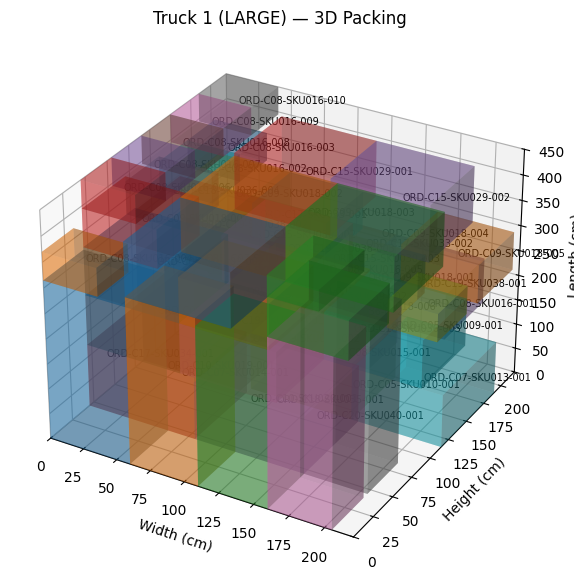

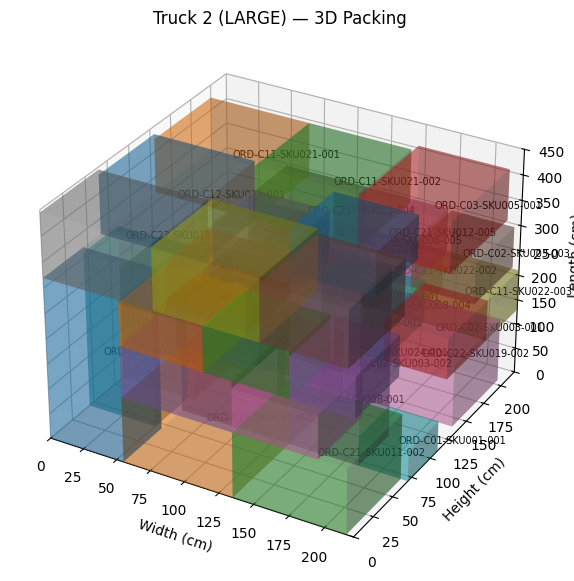

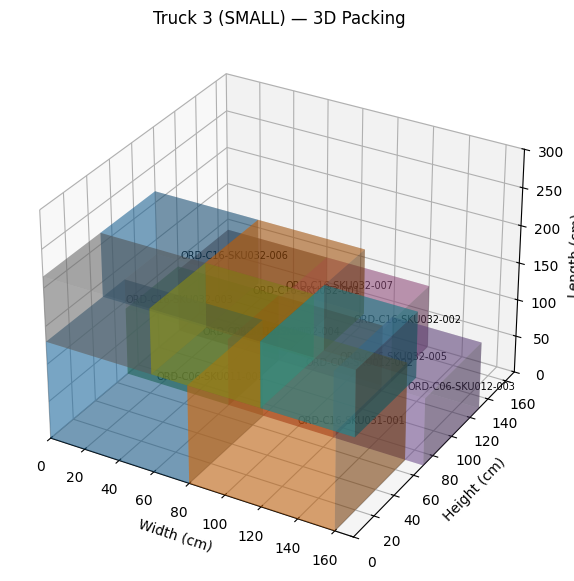

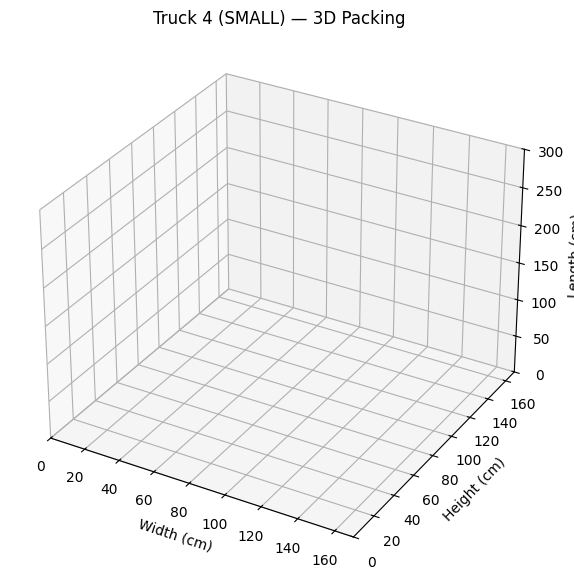

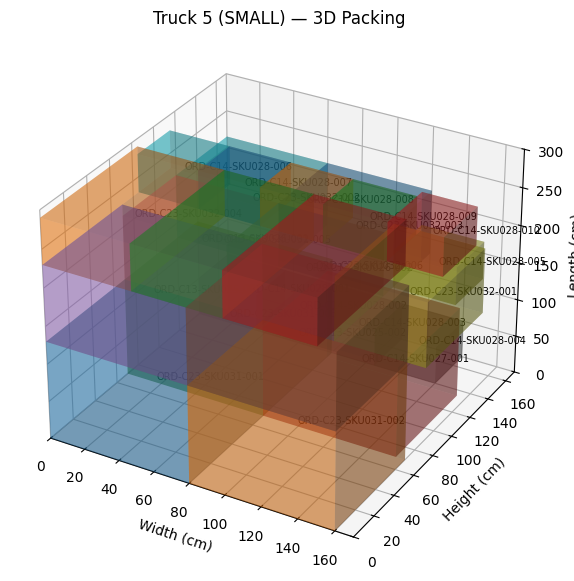

In [ ]:
def plot_packed_truck(vehicle_id):
    result = final_packings[vehicle_id]
    packed_bin = result["bin"]

    truck = truck_df.loc[
        truck_df.vehicle_id == vehicle_id
    ].iloc[0]

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")

    for item in packed_bin.items:
        x, y, z = [float(v) for v in item.position]
        dx, dy, dz = [
            float(v)
            for v in item.get_dimension()
        ]

        ax.bar3d(
            x, y, z,
            dx, dy, dz,
            alpha=0.35,
            shade=True
        )

        ax.text(
            x + dx / 2,
            y + dy / 2,
            z + dz / 2,
            item.name,
            fontsize=7
        )

    ax.set_xlim(0, float(truck["width_cm"]))
    ax.set_ylim(0, float(truck["height_cm"]))
    ax.set_zlim(0, float(truck["length_cm"]))

    ax.set_xlabel("Width (cm)")
    ax.set_ylabel("Height (cm)")
    ax.set_zlabel("Length (cm)")

    ax.set_title(
        f"{truck['truck_name']} ({truck['truck_type']}) — 3D Packing"
    )

    plt.show()


for vehicle_id in range(NUM_VEHICLES):
    plot_packed_truck(vehicle_id)

# Chapter 6 — Demo 2 Summary

**Talk-script anchor: A2-SUMMARY**

Main message: **same model, harder scenario, different operational result.**

## 22. What this version adds

### Real-time traffic is now part of the optimization input

TomTom Orbis Traffic Flow Vector Tiles provide road geometry plus current traffic-flow attributes such as `absolute_speed`, `relative_speed`, and closure status.

The notebook approximately map-matches those traffic segments to the OSMnx graph and creates:

```text
traffic_travel_time(edge)
```

Edges without TomTom coverage fall back to the original OSMnx travel time.

OR-Tools therefore chooses:

- which truck serves each customer
- customer visit order
- arrival times

while minimizing **traffic-aware travel time** plus a strong penalty on **total driver overtime**, and still respecting:

- payload weight
- aggregate volume
- customer time windows
- service time
- driver/truck qualification
- hard driver shift start
- soft driver shift end

### Packing remains a hard constraint

Every ordered unit is expanded into an individual physical box. A route may be good for traffic and time windows but is rejected if its assigned cargo cannot physically fit.

```text
Traffic-aware VRP solution
AND
every ordered physical box is 3D-packable
```

Only then is the delivery plan accepted.

### Driver overtime is an operational warning, not an automatic failure

The scheduled shift end is modeled as a soft upper bound.

```text
overtime minutes
    ↓
large objective penalty
    ↓
OR-Tools tries to move work to other drivers/trucks
    ↓
if overtime is still necessary:
report it explicitly for dispatcher action
```

This supports real operations where a dispatcher may negotiate a shift swap or accept limited overtime rather than canceling an otherwise feasible delivery plan.


## 23. Natural next extensions

1. Improve TomTom-to-OSM map matching with direction / OpenLR information
2. Compare **OSM baseline vs TomTom real-time** route assignments directly
3. Add TomTom Traffic Incidents as a separate accident / closure layer
4. Add historical traffic profiles for weekday × time-of-day planning
5. Move from a single live snapshot to a **time-dependent VRP**
6. Optimize driver-to-truck assignment itself instead of fixing it before the VRP
7. Add automatic **driver shift swapping** / relief-driver decisions
8. Add lunch breaks, split shifts, and legally required break rules
9. Add overtime wage rates that differ by driver or employment type
10. Add loading/unloading order constraints, fragile items, pallets, and irregular shapes

For **07A2**, the technical message is:

> **Traffic, customer constraints, truck capacity, physical packing, and workforce schedules interact. Python can optimize the delivery plan while treating driver overtime as a costly exception rather than an automatic failure.**
